---

Universidad Nacional de Asunción

Facultad de Ingeniería

# **Robótica 2**

---

**Integrantes:**
- Mathias Aguilar
- Héctor Velázquez
- Pablo Otazú
- Pedro Vera

**Fecha:** 08/11/2026

# Trabajo práctico: Robótica Social
## Cabeza social reactiva de 3 grados de libertad con visión artificial

**Nombre del robot:** Wall-E (proyecto Keepon pro)
**Repositorio:** https://github.com/HecVelaz/keepon-pro
**Versión / commit evaluado:** versión `v1.0-entrega` del 08/11/2026 (rama `main`, con todo el trabajo integrado). Los parámetros de este informe se leen de `config.yaml` de esa versión.
**Video de demostración (3 minutos, las 8 pruebas):** [https://youtu.be/raOJljv1mVU](https://youtu.be/raOJljv1mVU)

<a href="https://youtu.be/raOJljv1mVU">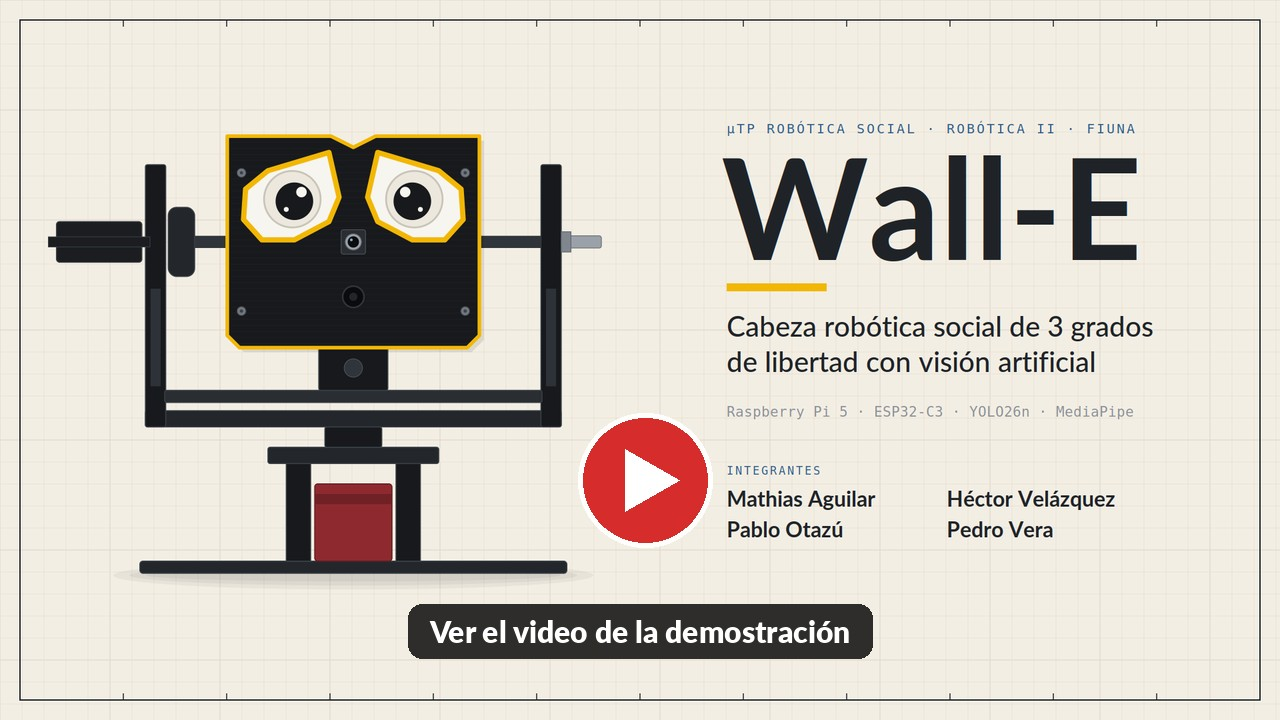</a>

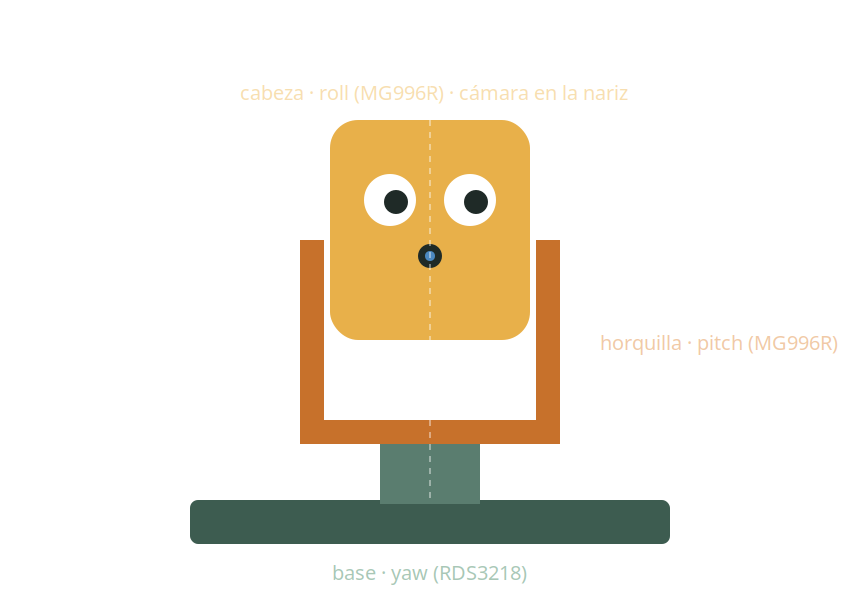<br><sub>Editable: <code>diagramas/01_esquema_keepon.drawio</code></sub>

> Las celdas de código ya están ejecutadas: el informe se lee sin correr nada. Si se ejecutan en Colab, descargan el repositorio público
> y leen los parámetros reales de `config.yaml`, los benchmarks y el escenario simulado; no hace falta el robot.
> En todo el informe se distingue lo **medido en el robot**, lo **probado en banco** y lo **probado en simulación**.

In [1]:
# Video de la demostración: las 8 pruebas del robot en 3 minutos (YouTube; ya se ve sin ejecutar la celda).
from IPython.display import IFrame
IFrame("https://www.youtube.com/embed/raOJljv1mVU", width=800, height=450, extras=["allowfullscreen"])

In [2]:
# Preparación: descarga el repositorio público y carga config.yaml, que concentra TODOS los parámetros del robot.
import os, subprocess, sys
RAMA = "v1.0-entrega"   # versión entregada (etiqueta del repositorio); "main" para la última
if not os.path.exists("keepon-pro"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", RAMA,
                    "https://github.com/HecVelaz/keepon-pro.git"], check=True)
sys.path.insert(0, "keepon-pro")

import yaml, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_colwidth", 80)
cfg = yaml.safe_load(open("keepon-pro/config.yaml", encoding="utf-8"))
commit = subprocess.run(["git", "-C", "keepon-pro", "log", "-1", "--format=%h %cs %s"], capture_output=True, text=True).stdout.strip()
print("Versión leída:", commit)
print("config.yaml con las secciones:", ", ".join(cfg))

Versión leída: 66c91a7 2026-11-08 Informe: ZIP (release v1.0-entrega), secuencia real del video, demo presencial y lo no medido indicado como tal
config.yaml con las secciones: neck, serial, camera, control, perception, camiseta, eventos, buzzer, sounds, priorities, ejes, cooldowns, gaze, focus, curiosidad, modos, observer, greeting


## 1. Resumen

Wall-E es una cabeza robótica con ojos sobre un cuello de 3 grados de libertad (yaw, pitch, roll), impresa en 3D y diseñada por el grupo.
Una cámara Camera Module 3 NoIR en la nariz entrega la imagen a una Raspberry Pi 5, que detecta personas con YOLO26n, rostros con
MediaPipe BlazeFace, la orientación de la cara con solvePnP y la pose del cuerpo con MediaPipe Pose. Con eso construye un modelo del mundo
con personas identificadas por ID y eventos filtrados en el tiempo (ME_MIRA, SALUDO, CAMISETA_OLIMPIA, CAMISETA_CERRO, SALIENDO). Seis
comportamientos proponen acciones y un **árbitro propio** asigna los dos recursos exclusivos (cuello y buzzer) según prioridades, interrupciones
y cooldowns. Una ESP32-C3 genera trayectorias suaves para los servos (perfil trapezoidal con curva S) y toca melodías en un buzzer pasivo, con watchdog y STOP enclavado.
En el robot real la detección de personas corre a 12–17 Hz y el lazo de decisión a 36–39 Hz.

**Funciones demostradas en el robot:** seguimiento de la persona con foco e histéresis, Observador que explora la escena (barridos lentos, sacadas y roll), saludo (3 cabeceos + R2D2), Olimpia →
polca sin dejar de seguir (una vez por aparición), Cerro → abucheo, remeras lisas roja y azul sin falsos positivos, cambio de modo con beep, curiosidad (inclinación
de roll), HOME del operador y vuelta a HOME al apagar, overlay de monitoreo y log con marca de tiempo, control desde el celular.
**Limitaciones principales:** ME_MIRA casi no se activaba en las pruebas (cámara sin calibrar con tablero), por lo que los modos Tímido y
Atrevido están probados solo en simulación; Maleducado y la versión de la mirada por objetivo (05/11) también falta probarlos en el robot;
la latencia evento → respuesta está estimada (≈ 130–170 ms) pero no medida de punta a punta; el roll vibra al girar hacia la derecha desde la zona negativa y el yaw en barridos lentos.

## 2. Objetivos y alcance

### Objetivo general

Construir una cabeza social que perciba señales sociales (presencia, mirada, saludo, camiseta, salida del campo visual) y responda con
mirada, gestos de cabeza y sonidos de forma coherente y reactiva: sin bloquearse, sin que dos comportamientos manden a la vez al mismo
actuador y con personalidades que se cambian en ejecución.

### Objetivos específicos

- **Control de los tres ejes:** trayectorias suaves con límites de posición, velocidad y aceleración, HOME calibrado, watchdog y STOP.
- **Percepción y foco de atención:** detectar personas con ID a ≥ 10 Hz, estimar quién mira al robot, y elegir a quién mirar con histéresis.
- **Comportamientos y personalidades:** Observador, Seguimiento, Saludo, Olimpia, Cerro y los modos Neutro, Tímido, Atrevido y Maleducado.
- **Arbitraje y gestión de recursos:** un solo dueño del cuello y del buzzer, prioridades, interrupciones, cooldowns y anti-repetición.
- **Validación y monitoreo:** overlay en vivo, log de transiciones con marca de tiempo, 257 tests automáticos y simulación del robot completo.

### Estado de las funciones al entregar

| Función / requisito | Implementado | Validado en el robot | Evidencia / limitación |
|---|---|---|---|
| Plataforma y control de 3 GDL (T1) | Sí | Sí | v6 R4 armado; límites, vmax y amax en firmware; 30/30 pruebas en la ESP32; curva S en todos los movimientos (08/11); signo y cero del roll verificados montados (08/11). Vibra el roll girando a la derecha en la zona negativa. |
| Percepción de eventos (T2) | Sí | Parcial | PERSONA, SALUDO y camisetas validados en el robot. ME_MIRA casi no se activa; SALIENDO probado solo en simulación. |
| Control de mirada (T3) | Sí | Sí | Seguimiento real con el modo `velocidad`; el modo `objetivo` (05/11) está probado en simulación. Pérdida < 1 s: mantiene. |
| Selección del foco (T4) | Sí | Parcial | Prioridad a quien mira, tamaño + centrado, histéresis 1,5 s: tests y simulación; falta prueba con varias personas. |
| Comportamientos y modos (T5) | Sí | Parcial | Saludo, polca, abucheo, cambio de modo y curiosidad en el robot; Tímido, Atrevido y Maleducado en simulación. |
| Arbitraje y robustez (T6) | Sí | Sí | 0 violaciones de recursos en el escenario de 30 s; polca + seguimiento conviven en el robot. Latencia sin medir de punta a punta. |
| Monitoreo y registro (T7) | Sí | Sí | Overlay con personas e ID, objetivo, eventos, modo, dueños y ángulos; log CSV en `logs/`. |

## 3. Mecanismo y electrónica (T1)

### 3.1. Configuración mecánica final

La estructura es el diseño propio **v6 R4** (`docs/diseno_v6/`), impreso en 3D y armado desde el 03/11. La base aloja el servo de yaw, la
ESP32 y la bornera de 6 V; sobre el yaw va una horquilla con el servo de pitch, que mueve una cuna; sobre la cuna, el servo de roll mueve la
cabeza con un disco de 25 dientes. La **Raspberry Pi va dentro de la cabeza** porque la cinta de la cámara mide ~150 mm, y la cámara es la
nariz, en el centro de la cara entre los dos ojos. Los ejes de pitch y roll se cruzan en (0, 0, 163) mm, a la altura del centro óptico: al
girar, la cámara rota sobre sí misma. **HOME** = 0°/0°/0°, mirada al frente.

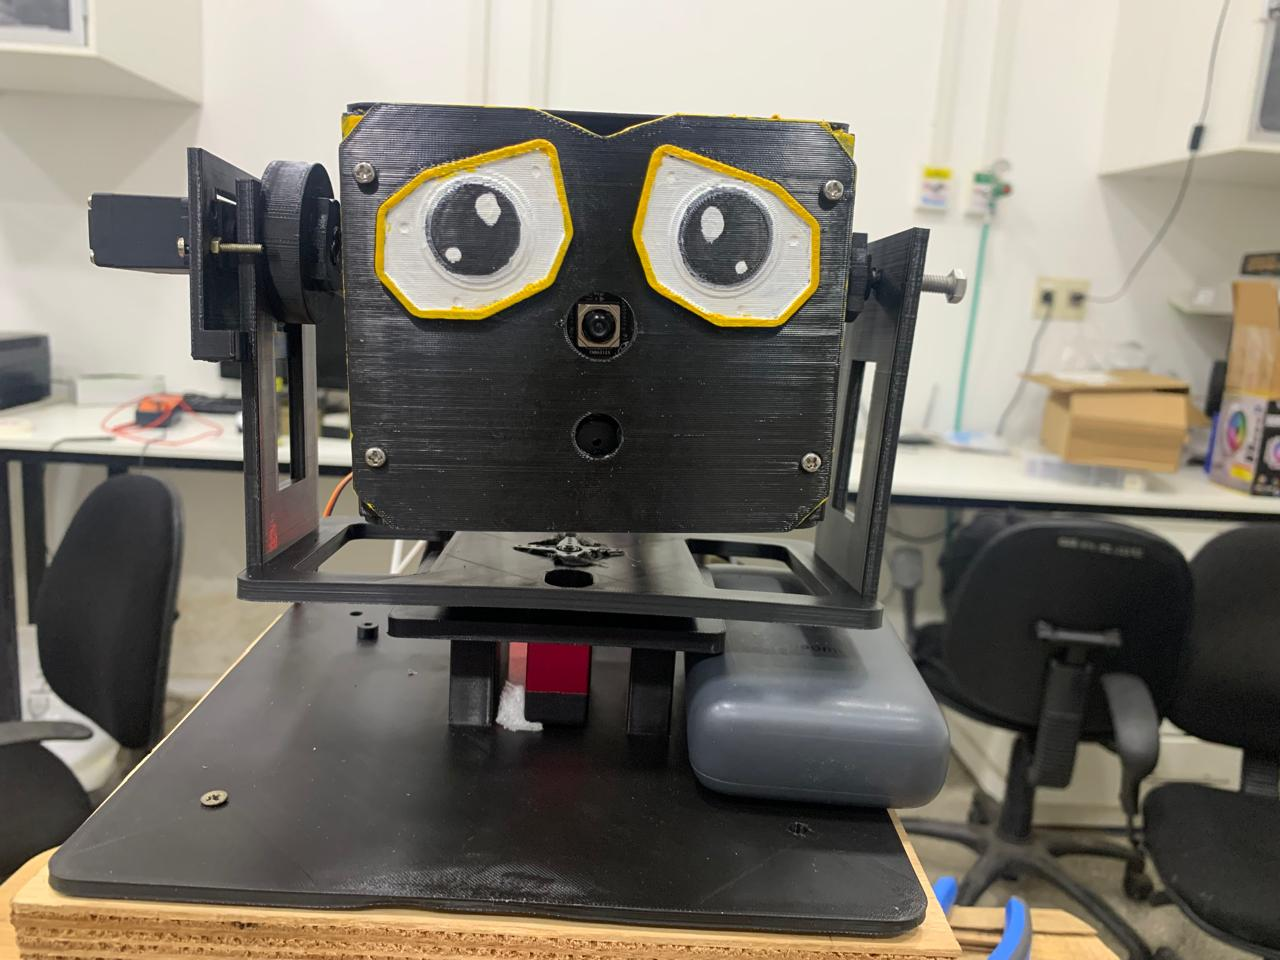

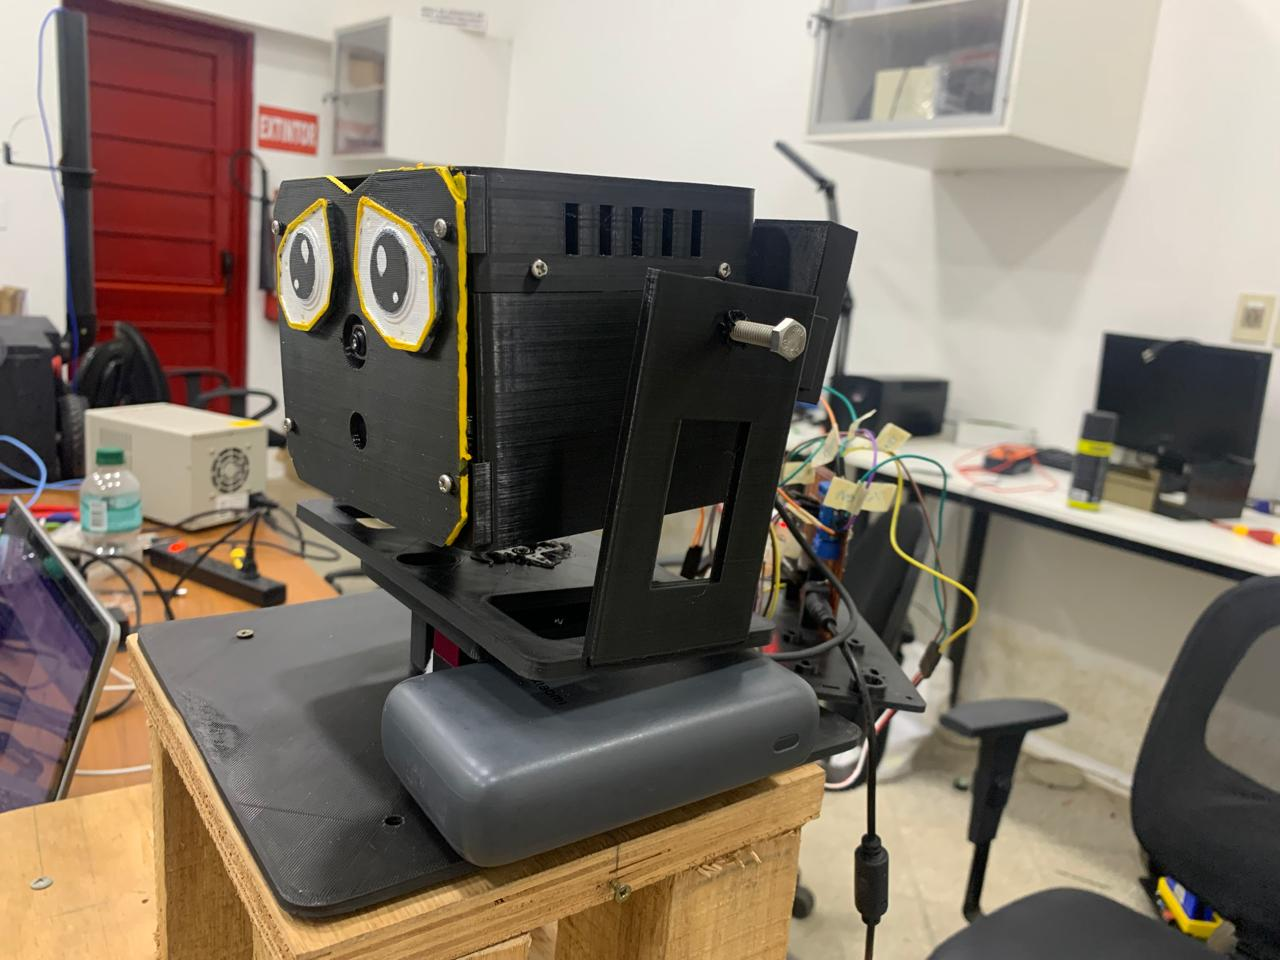 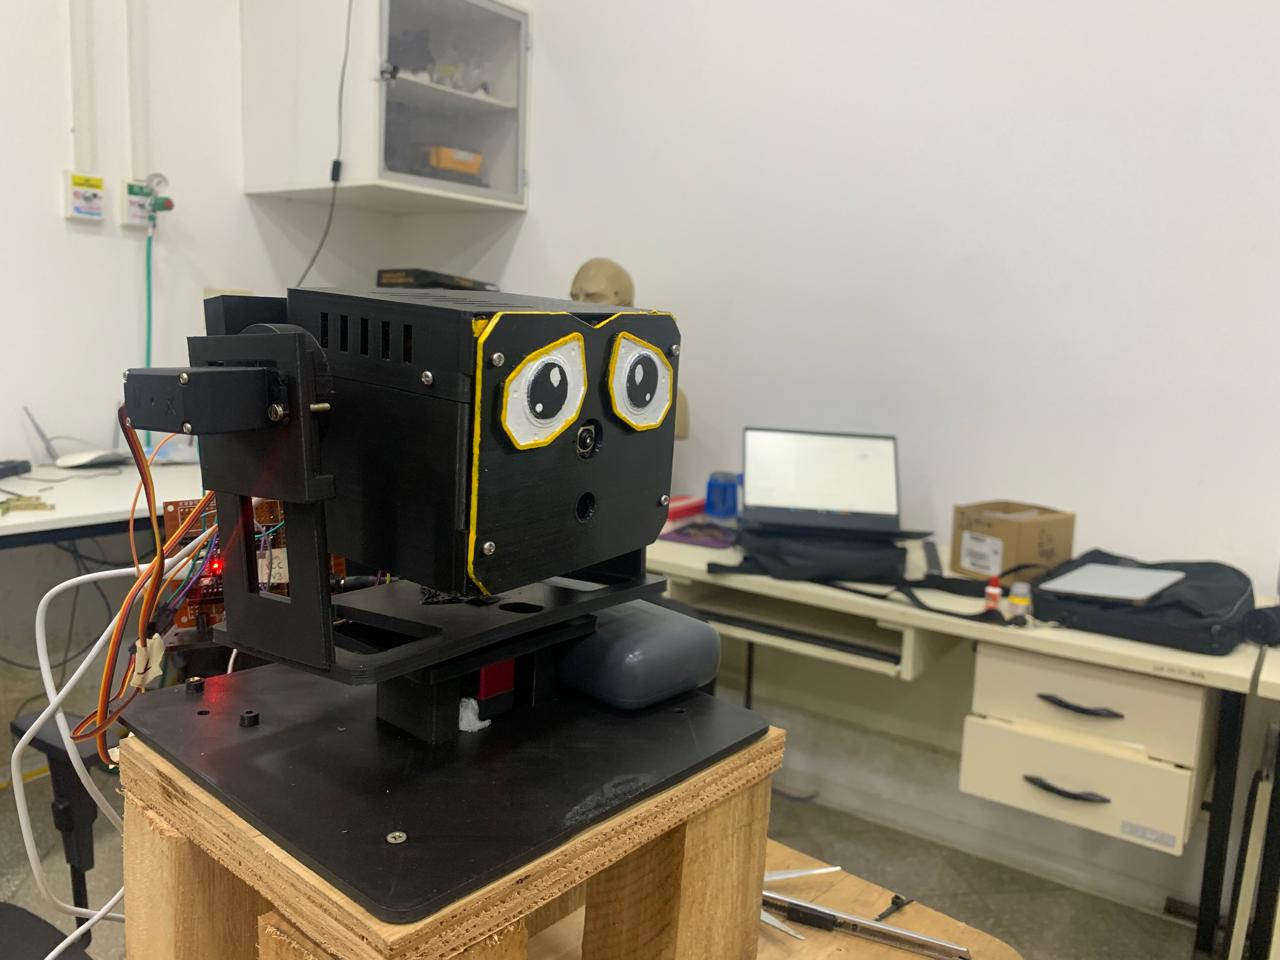

*Foto. Wall-E armado (v6 R4): de frente, la cara con los ojos, la cámara como nariz y el buzzer debajo; de costado, la horquilla de pitch,
el servo de roll detrás de la cabeza y el powerbank de la Pi en la base.*

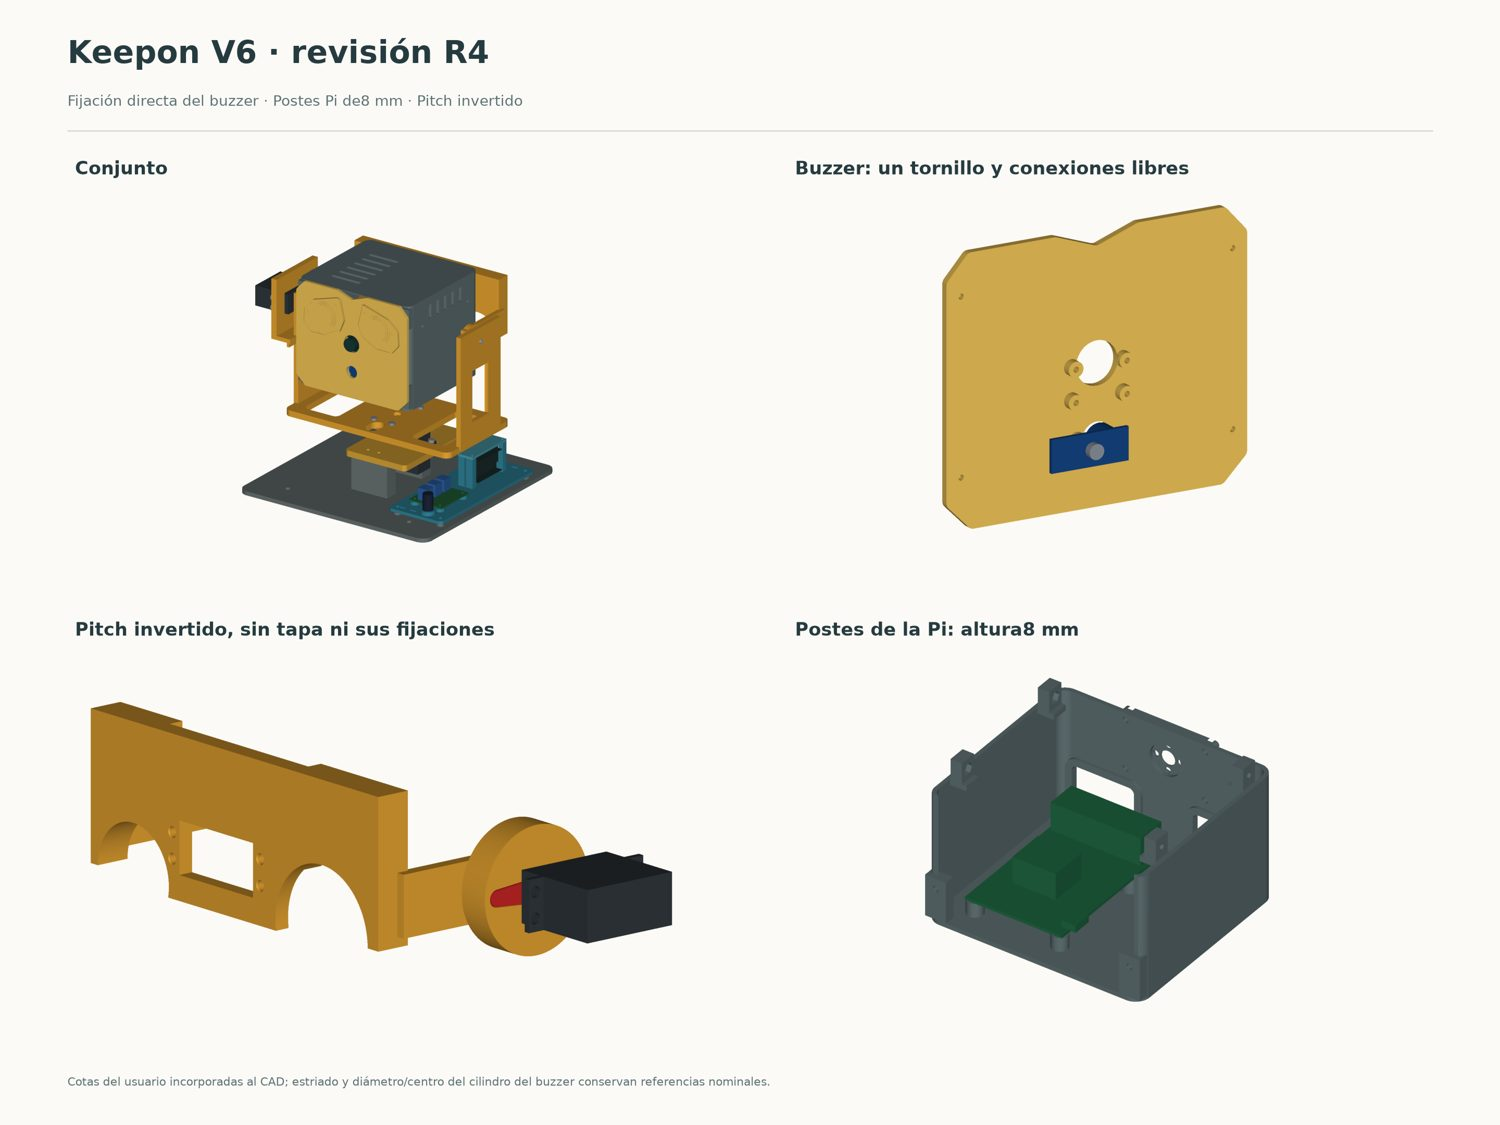

*Figura 1. Vista CAD del v6 R4: conjunto, cara con el buzzer, cuna de pitch con su servo y caja de la cabeza con la Pi.*

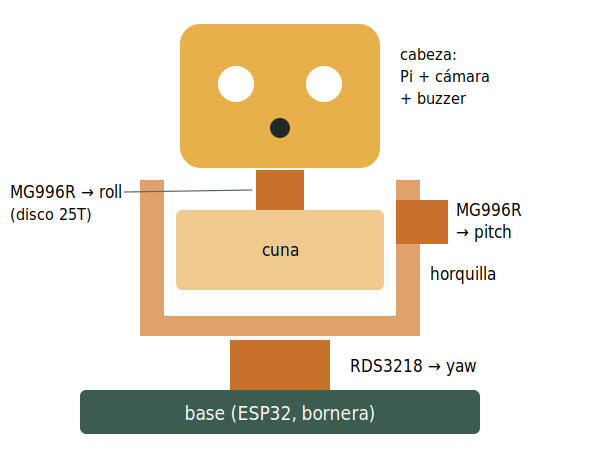<br><sub>Editable: <code>diagramas/02_cadena_cinematica.drawio</code></sub>

*Figura 2. Cadena cinemática: qué servo mueve a qué.*

| Eje | Servomotor instalado | HOME | Límite mínimo | Límite máximo | Velocidad máxima | Aceleración máxima |
|---|---|---|---|---|---|---|
| Yaw | DSSERVO RDS3218 (270°) | 0° | −70° | +70° | 180 °/s | 600 °/s² |
| Pitch | TowerPro MG996R | 0° | −20° | +30° | 120 °/s | 400 °/s² |
| Roll | TowerPro MG996R | 0° | −20° | +20° | 250 °/s | 900 °/s² |

**Calibración.** Cada servo se caracterizó en un banco (`pruebas_servos/`): grados por µs, banda muerta y sentido de giro. Montado el robot,
se calzó cada horn en 1500 µs con la cabeza al frente (HOME) y se midieron los extremos: por ejemplo, pitch +30° = 1174 µs y −20° = 1717 µs.
El **signo** de cada eje deja la misma convención para los tres (yaw + = derecha, pitch + = arriba, roll + = horario visto desde atrás).
El del roll se verificó montado el 08/11: estaba al revés (roll + inclinaba a la izquierda, signo copiado del MG996R anterior) y quedó en +1. Los
recorridos reales son los sugeridos por la consigna: el roll se limitó a ±20° porque a +25° queda al límite de la pared y a +30° toca.

**Movimientos suaves.** La ESP32 genera, a 100 Hz, un perfil trapezoidal de velocidad por eje con `vmax` y `amax` (sección 3.3), y desde el
08/11 lo pasa por una **curva S**: la posición que va al servo es el promedio del trapecio en una ventana de `suavizado_s` (0,10 / 0,10 / 0,15 s).
Así la aceleración cambia en rampa en vez de saltar: el jerk del yaw bajó de 60 000–104 000 a ≤ 12 000 °/s³ (≤ 2·amax/ventana), sin pasar
`vmax` ni `amax` ni el objetivo; cada movimiento dura ~0,1 s más (25° de yaw: de ~0,4 a 0,49 s, celda de abajo). Los servos vibran cuando avanzan despacio (de a
saltitos, por su banda muerta) y no vibran quietos; bajar `vmax`/`amax` lo empeoró, y en el roll **sin curva S vibraba más**: los saltos de
aceleración también hacen vibrar. Por eso los movimientos son **rápidos, pocos y sin saltos de aceleración**: la mirada salta a la persona en un
solo movimiento y queda quieta (sección 6). En el roll, `vmax` 250 °/s y `amax` 900 °/s² están en prueba.

| Eje | Historia de los servos |
|---|---|
| yaw | Se probaron dos RDS3218: el n.º 1 vibraba quieto cerca de 1500 µs; al intercambiarlos la vibración siguió al servo → descartado. |
| pitch | HS-7955TG (09/10–05/11) → MG996R nuevo: el HS metía mucho ruido en la alimentación. |
| roll | MG996R n.º 1 (13/10–05/11) → MG996R nuevo: el n.º 1 tenía ~10° de banda muerta, compensada en el firmware con 151 µs según el sentido. El 08/11 se cambió por otro MG996R igual: cero en 1500 µs (llegando desde la izquierda), sin compensación; vibra solo girando a la derecha en la zona negativa (−20…0), con cualquier perfil (falta el banco). |

In [3]:
# Calibración de cada servo (neck.servos) y conversión grados -> µs, igual que el firmware:
#   pulso = centro + signo * ángulo / (grados por µs), recortado a [min, max]
def grados_a_us(eje, angulo):
    s = cfg["neck"]["servos"][eje]
    k, d = s["grados_por_us"], s["signo"] * angulo
    if isinstance(k, list):          # yaw: un valor para cada lado de 1500 µs
        k = k[0] if d < 0 else k[1]
    return min(max(s["centro_us"] + d / k, s["min_us"]), s["max_us"])

servos = pd.DataFrame(cfg["neck"]["servos"]).T[["centro_us", "grados_por_us", "min_us", "max_us", "signo"]]
display(servos)
filas = []
for e in ("yaw", "pitch", "roll"):
    lo, hi = cfg["neck"]["limits"][e]
    filas.append({"eje": e, "mínimo": f"{lo:+g}° → {grados_a_us(e, lo):.0f} µs", "HOME": f"0° → {grados_a_us(e, 0):.0f} µs",
                  "máximo": f"{hi:+g}° → {grados_a_us(e, hi):.0f} µs"})
display(pd.DataFrame(filas).set_index("eje"))

,centro_us,grados_por_us,min_us,max_us,signo
pitch,1500.0,0.092,1100.0,1800.0,-1.0
yaw,1500,"[0.13, 0.136]",950,2020,-1
roll,1500,0.092,1000,2000,1


,mínimo,HOME,máximo
eje,,,
yaw,-70° → 2015 µs,0° → 1500 µs,+70° → 962 µs
pitch,-20° → 1717 µs,0° → 1500 µs,+30° → 1174 µs
roll,-20° → 1283 µs,0° → 1500 µs,+20° → 1717 µs


### 3.2. Electrónica y alimentación

| Componente | Modelo real | Función | Conexión / alimentación |
|---|---|---|---|
| Equipo de procesamiento | Raspberry Pi 5, 4 GB, Ubuntu 24.04 + ROS 2 Jazzy | Percepción y lógica | En la cabeza; cámara por CSI; ESP32 por USB |
| Microcontrolador | ESP32-C3-DevKitM-1 (clon con CH340) | Control de actuadores | USB serie a la Pi (datos y 5 V); señales a los servos y al buzzer |
| Cámara | Camera Module 3 NoIR (IMX708), 640×480 a 30 fps | Captura de imagen | CSI a la Pi; montada invertida (`orientation_deg: 180`) |
| Buzzer pasivo | Módulo MH-FMD (con transistor PNP) | Sonidos por frecuencia variable | VCC a 3V3 de la ESP32, I/O en GPIO5 (activo en bajo) |
| Alimentación del procesamiento | Powerbank Xiaomi PB2020MI, 20 000 mAh | Alimenta la Pi (~9 h) | 5 V / 3 A |
| Alimentación de los servos | Fuente de laboratorio | Alimenta los 3 servos | 6,0 V, límite de corriente 4–5 A (uso normal 2–3 A) |

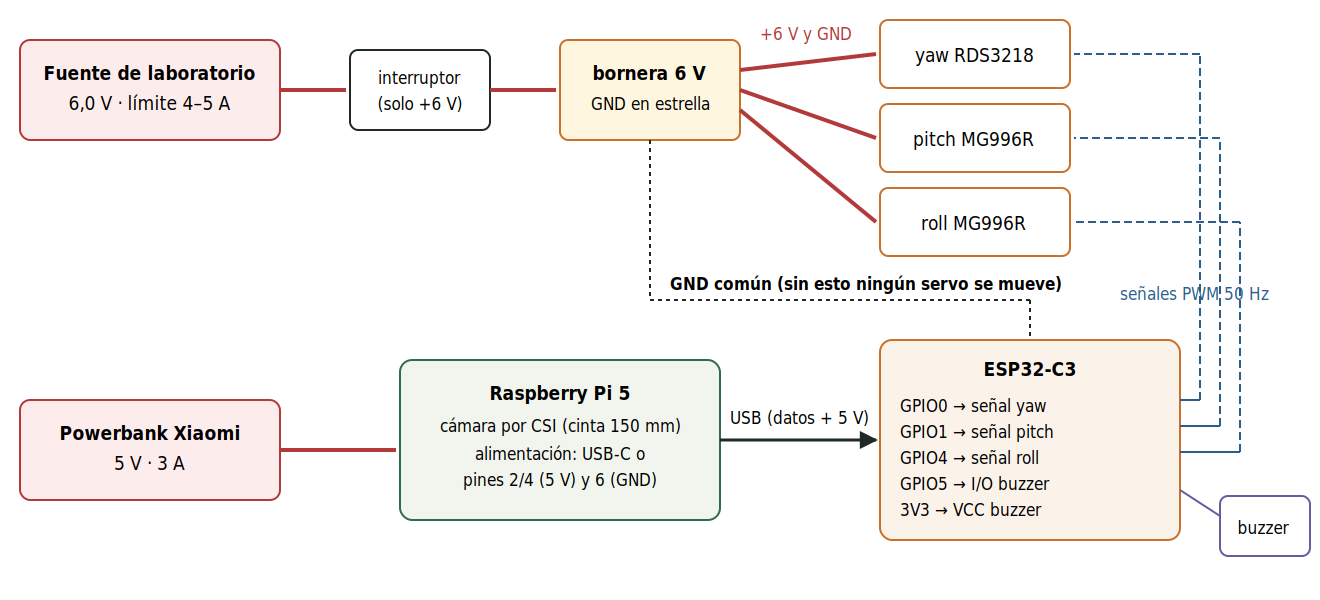<br><sub>Editable: <code>diagramas/03_diagrama_electrico.drawio</code></sub>

*Figura 3. Diagrama eléctrico. Dos fuentes separadas, unidas solo por el GND (sin GND común ningún servo se mueve).*

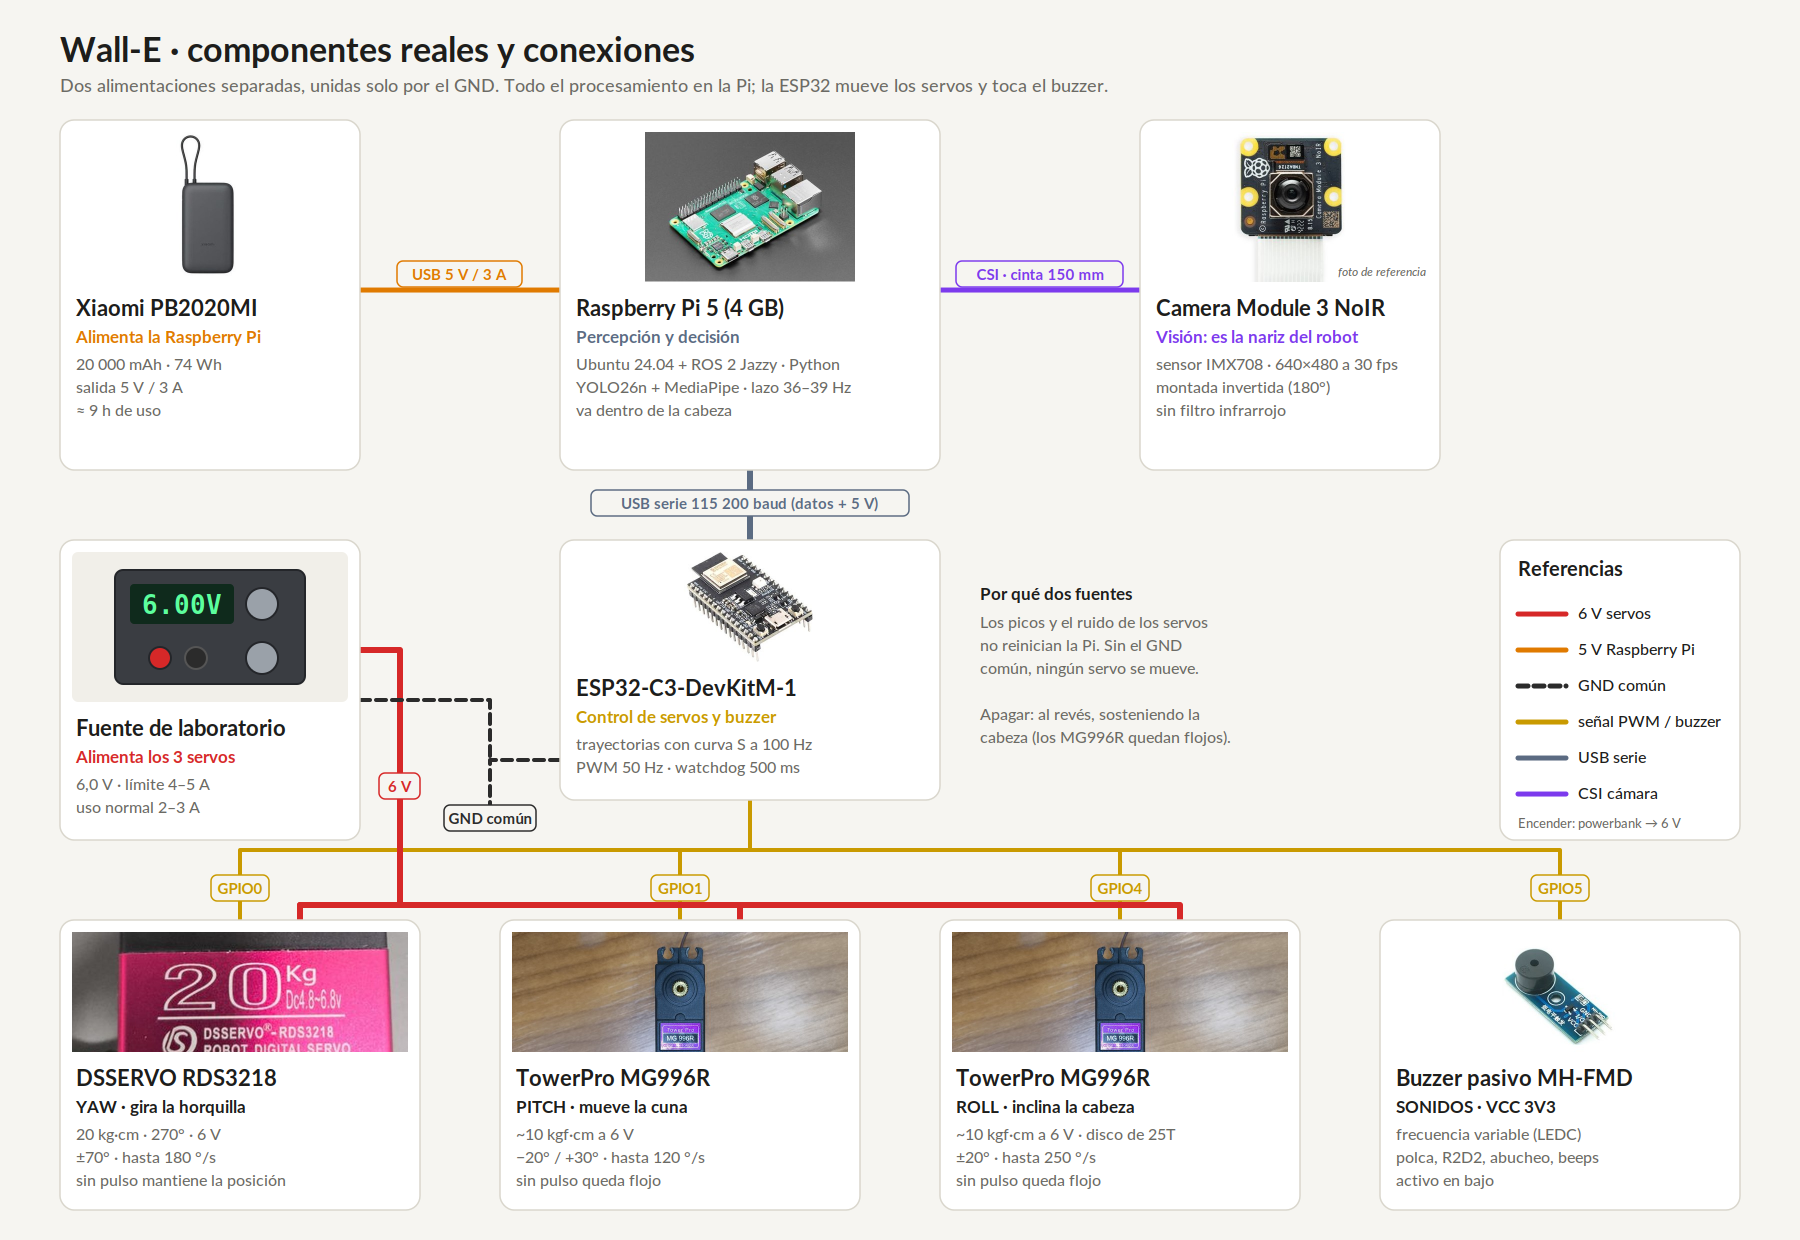

*Figura 3b. Componentes reales de Wall-E con sus datos y conexiones: powerbank, Raspberry Pi 5, cámara, ESP32-C3, fuente de 6 V, los tres
servos y el buzzer. Fotos de `docs/hardware/fotos/` y `docs/hardware/diagrama_sistema/fotos/` (la de la cámara es de referencia); se regenera con
`scripts/diagrama_componentes.py`.*

| Pin de la ESP32-C3 | Uso | Nota |
|---|---|---|
| GPIO0 / GPIO1 / GPIO4 | servos yaw / pitch / roll | PWM 50 Hz, 14 bits, un timer LEDC compartido |
| GPIO5 | buzzer | timer LEDC aparte (cambiar de nota no altera el PWM de los servos) |
| GPIO20 / 21 | UART0 (USB serie) | reservados |
| GPIO2 / 8 / 9 y 18 / 19 | strapping y USB nativo | no se usan |

**Secuencia de encendido:** primero el powerbank (Pi), con la cabeza cerca de HOME, y después los 6 V de los servos. **Parada:** al revés,
sosteniendo la cabeza (los MG996R sin pulso quedan flojos). Los servos no tienen realimentación: el primer pulso los lleva a HOME a toda
velocidad, por eso la cabeza tiene que estar cerca. Se eligieron dos fuentes separadas para que los picos y el ruido de los servos no reinicien la Pi.

### 3.3. Protocolo de comunicación

USB serie (UART0 por el CH340) a **115 200 baudios**, líneas ASCII de hasta 64 caracteres terminadas en `\n`. Cada orden lleva un número de
secuencia `seq` para asociar la respuesta: `ACK seq [CLIPPED]`, `DONE seq` al terminar un sonido, `ERR seq MOTIVO` y `STATE seq ESTADO yaw pitch roll SONIDO`.
Una línea mal formada se descarta con `ERR`, nunca corta el programa. **Pérdida de comunicación:** si la ESP32 no recibe nada válido en 500 ms
(watchdog), corta el sonido, frena y mantiene la postura; la Pi manda `PING` cada 200 ms si no mandó otra cosa. Si la ESP32 se reinicia, avisa
con `HELLO 0`: la Pi cancela todo, toma HOME como referencia, reabre la sesión y reenvía el STOP si estaba activo.

| Orden | Formato real | Respuesta / efecto | Ejemplo |
|---|---|---|---|
| Movimiento | `J seq yaw pitch roll` | `ACK seq` (o `CLIPPED` si se recortó); reemplaza la referencia anterior | `J 7 25.0 5.0 0.0` |
| Sonido | `S seq NOMBRE` | `ACK seq` y `DONE seq` al terminar | `S 8 R2D2` |
| STOP / reanudación | `STOP seq` / `RESUME seq` | Frena, corta el sonido y rechaza `J S HOME` hasta `RESUME` | `STOP 12` |
| Cambio de modo | No pasa por la ESP32: es estado de la Pi. El operador manda `n`, `t`, `a` o `m` (panel o `keepon`) y la Pi toca el beep del modo con `S seq BEEP_*` | Beep distintivo de confirmación | `S 15 BEEP_TIMIDO` |
| Otros | `HELLO 1`, `PING seq`, `HOME seq`, `CANCEL seq SOUND`, `VOL seq PCT` | Sesión, keepalive + `STATE`, ir a HOME, cortar sonido, volumen | `VOL 9 50` |

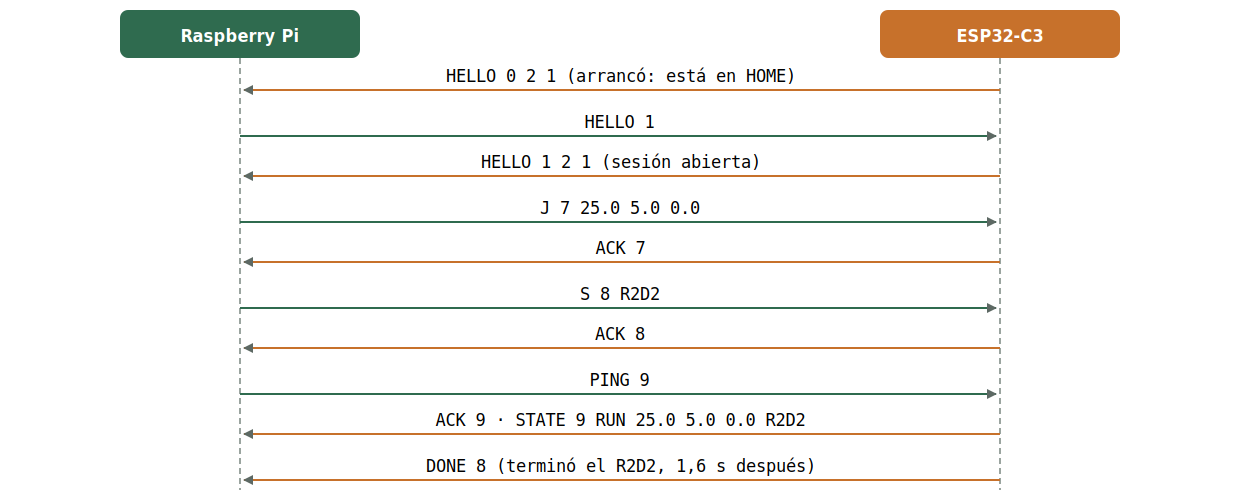<br><sub>Editable: <code>diagramas/04_sesion_serie.drawio</code></sub>

*Figura 4. Ejemplo de sesión entre la Pi y la ESP32.*

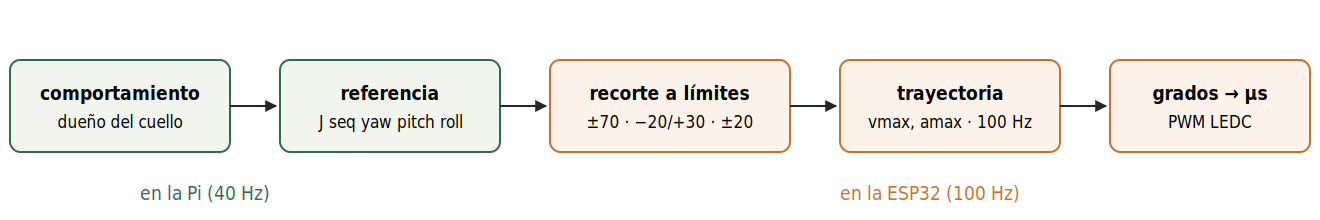<br><sub>Editable: <code>diagramas/05_cadena_de_control.drawio</code></sub>

*Figura 5. Cadena de control de un eje: la Pi manda la referencia; la ESP32 la recorta a los límites, genera la trayectoria a 100 Hz y la
convierte a pulso.* El cálculo de la trayectoria es discreto y exacto (`keepon/trajectory.py`): las posiciones enviadas nunca superan `amax`
y el último paso cae justo en el objetivo; la curva S (promedio móvil del trapecio) conserva esas dos propiedades. El firmware tiene una copia en C++ y 36+ tests comparan las dos paso a paso.

**Medido en la ESP32 real (14/10):** 30/30 pruebas OK; PING → ACK 4,4 ms de media (máx. 4,9); un movimiento a 70/30/−20 llega en 0,68 s
(el simulador predice 0,69 s); watchdog a los ~490 ms.

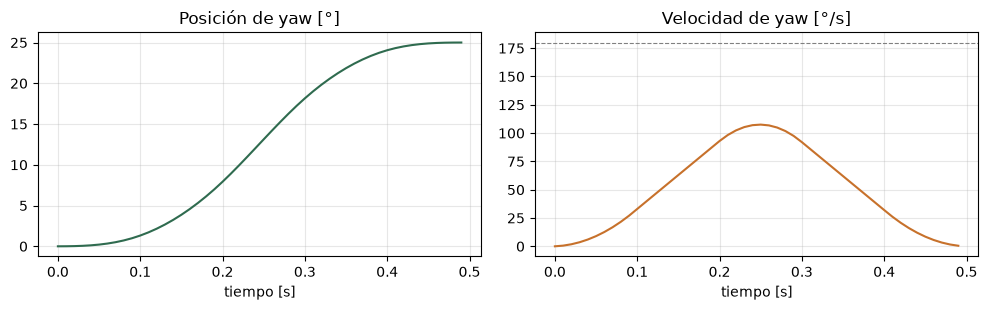

Llega a 25° en 0.49 s · vmax = 180.0 °/s · amax = 600.0 °/s² · curva S = 0.1 s


In [4]:
# Simulación con el generador de trayectorias del robot (el firmware ejecuta la misma lógica a 100 Hz):
# perfil trapezoidal (vmax, amax) suavizado con la curva S (neck.suavizado_s).
from keepon.trajectory import Neck
neck = Neck.from_config(cfg)
neck.set_target(25.0, 0.0, 0.0)          # girar 25° en yaw
t, pos = [0.0], [neck.pos[0]]
while neck.moving():
    neck.step(0.01)
    t.append(t[-1] + 0.01); pos.append(neck.pos[0])
vel = [0.0] + [(b - a) / 0.01 for a, b in zip(pos, pos[1:])]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(t, pos, color="#2f6b4f"); ax[0].set_title("Posición de yaw [°]"); ax[0].set_xlabel("tiempo [s]")
ax[1].plot(t, vel, color="#c7712b"); ax[1].set_title("Velocidad de yaw [°/s]"); ax[1].set_xlabel("tiempo [s]")
ax[1].axhline(cfg["neck"]["vmax"][0], ls="--", color="gray", lw=0.8)
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Llega a 25° en {t[-1]:.2f} s · vmax = {cfg['neck']['vmax'][0]} °/s · amax = {cfg['neck']['amax'][0]} °/s²"
      f" · curva S = {cfg['neck']['suavizado_s'][0]} s")

## 4. Percepción y modelos de IA (T2)

### 4.1. Modelos y librerías

| Modelo / librería | Versión | Tarea | Fuente / enlace | Configuración usada |
|---|---|---|---|---|
| YOLO26n (Ultralytics) + NCNN | ultralytics 8.4.153, ncnn 1.0.20260526 | Personas | https://github.com/ultralytics/ultralytics · https://github.com/Tencent/ncnn | Exportado a NCNN con entrada fija de 256 px, confianza 0,4, clase persona |
| MediaPipe BlazeFace + OpenCV solvePnP | MediaPipe 1.0.1, OpenCV 4.11 | Rostros / mirada | https://github.com/google-ai-edge/mediapipe · https://opencv.org | Sobre un recorte de 192 px de la cabeza; 6 puntos → orientación de la cara; hasta 3 rostros por cuadro |
| MediaPipe Pose (lite) | MediaPipe 1.0.1 | Pose / manos | https://github.com/google-ai-edge/mediapipe | Hasta 2 personas, máx. 30 Hz; hombros y muñecas con visibilidad ≥ 0,5 |
| Reglas propias de color y patrón (`keepon/camiseta.py`) | desarrollo propio | Camisetas | — | Torso desde los hombros de MediaPipe; HSV con umbrales medidos con la NoIR |
| camera_ros (libcamera) | ROS 2 Jazzy | Captura | https://github.com/christianrauch/camera_ros | 640×480 a 30 fps, rotación de 180° |

**Preprocesamiento y resolución.** La cámara entrega 640×480; YOLO trabaja con la imagen reducida a 256 px (a 480 px tardaba 79 ms y saturaba
la CPU; a 256 px tarda 18 ms y detecta a 2 de 2 personas a 1,5 m en el 100 % de los cuadros).
**Seguimiento por ID:** tracker propio por solapamiento de cajas (IoU); el ByteTrack de Ultralytics costaba ~68 ms por cuadro en la Pi.
**Asociación:** los rostros se buscan en un recorte de la cabeza de cada caja de YOLO (así quedan asociados al ID); las poses de MediaPipe no
traen ID y se asocian a la persona cuya caja contiene sus hombros.
**Ejecución:** dos procesos fijados a núcleos (personas + rostros en 0-1, pose en 2-3), porque NCNN y MediaPipe no liberan el GIL y con hilos no
había paralelismo (2,04 s contra 2,11 s en serie).
**Límites:** Face Landmarker (478 puntos) se descartó porque tardaba ~49 ms por cara y no encontraba rostros lejanos; la pose queda en 7–10 Hz.

**Camisetas (reglas de color y patrón).** Se ubica el torso con los hombros (de 0,15 a 1,1 anchos de hombros debajo, sin el 10 % de cada lado),
se clasifica cada píxel en HSV y se busca el patrón:
- **Olimpia:** el torso en 8 franjas horizontales; una oscura (brillo ≤ 110) con franjas blancas (saturación ≤ 60) arriba y abajo, al menos 1,6 veces más claras.
- **Cerro:** el torso en 8 columnas; al menos 2 rojas y 2 azules separadas por un borde vertical, y ≥ 20 % de píxeles de cada color. No se exigen
  rayas porque la titular 2026 es mitad roja y mitad azul.

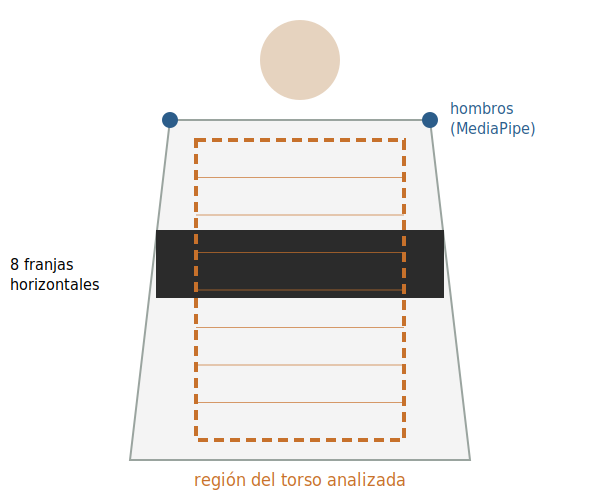<br><sub>Editable: <code>diagramas/06_region_torso.drawio</code></sub>

### 4.2. Definición operativa de eventos

| Evento | Señal / criterio | Umbral de confianza o geométrico | Confirmación temporal | Criterio para dejar de detectarlo | Asociación por ID |
|---|---|---|---|---|---|
| PERSONA | Caja de YOLO clase persona | Confianza ≥ 0,4 | Inmediata (el tracker mantiene el ID entre cuadros) | El objetivo se mantiene 1 s sin verse; después se libera | ID del tracker IoU |
| ME_MIRA | Ángulo entre el eje de la cara (solvePnP) y la línea cara → cámara | < 15° (`looking_deg`) | 0,5 s seguidos mirando | 0,3 s seguidos sin mirar | Rostro buscado dentro de la caja de cada ID |
| SALUDO | Muñeca por encima del hombro que oscila de costado | ≥ 0,1 hombros sobre el hombro; vaivén ≥ 0,25 anchos de hombros | 2 ciclos dentro de 2,5 s → un evento | La mano tiene que bajar 0,4 s para contar otro saludo (un gesto = una respuesta) | Hombros de la pose dentro de la caja del ID |
| CAMISETA_OLIMPIA | Franja oscura horizontal entre franjas blancas en el torso | Contraste ≥ 1,6; blanco con saturación ≤ 60; franja con brillo ≤ 110 | 6 cuadros de pose seguidos | 6 cuadros seguidos sin ella | Por persona (pose → ID) |
| CAMISETA_CERRO | Rojo y azul en partes grandes separados por bordes verticales | ≥ 2 columnas de cada color, ≥ 20 % de píxeles de cada uno | 6 cuadros de pose seguidos | 6 cuadros seguidos sin ella | Por persona (pose → ID) |
| SALIENDO | Cerca del borde y alejándose, o el yaw en su límite | A < 15 % del ancho del borde y ≥ 80 px/s hacia afuera; o yaw a < 4° del límite | La condición dura 0,2 s | Falta 0,6 s | Solo para la persona objetivo |

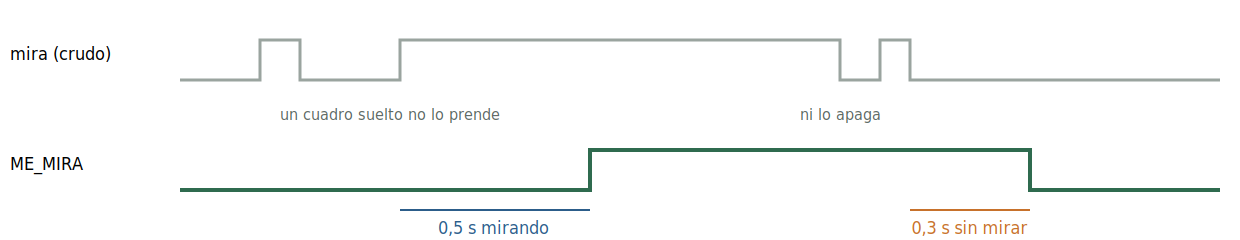<br><sub>Editable: <code>diagramas/07_histeresis_me_mira.drawio</code></sub>

*Figura 6. Histéresis temporal: un cuadro suelto no prende ni apaga el evento.*

### 4.3. Datos y condiciones de prueba

Las pruebas se hicieron en el laboratorio con luz LED, a distancias de 1,2 / 1,8 / 2,5 m, con integrantes del grupo como sujetos. Las
camisetas se grabaron con la cámara del robot en tomas de 60 s (`pruebas_camisetas/grabar.sh`). Los videos quedaron solo en la Pi, fuera del
repositorio, y se borran al cerrar el detector: **no se guardan imágenes de personas en el repositorio**, y solo se grabó a integrantes que aceptaron.
Las imágenes de referencia del repositorio son fotos de la camiseta sola, sin personas, con su fuente y licencia.

**Cámara.** Sin calibración propia con tablero: se usan fx/fy de otra cámara (campo de 37,3°) y el centro óptico en el centro de la imagen.
**Colores con la NoIR** (sin filtro infrarrojo): el azul marino de Cerro se ve violeta (H 116–145) y la franja negra de Olimpia, marrón violácea;
los umbrales HSV se midieron sobre las prendas reales con esta cámara y esta luz.

**Falsos positivos.** Las prendas lisas no cumplen ningún patrón: una roja o azul lisa no tiene los dos colores separados por un borde, y una
blanca lisa no tiene la franja oscura. Resultados con la cámara del robot: roja lisa 0 %, azul marino lisa 0 %. **Persisten:** la camiseta del
Barcelona es casi igual a la de Cerro por color y patrón, y la remera blanca lisa solo se probó con una imagen sintética.

## 5. Arquitectura del sistema

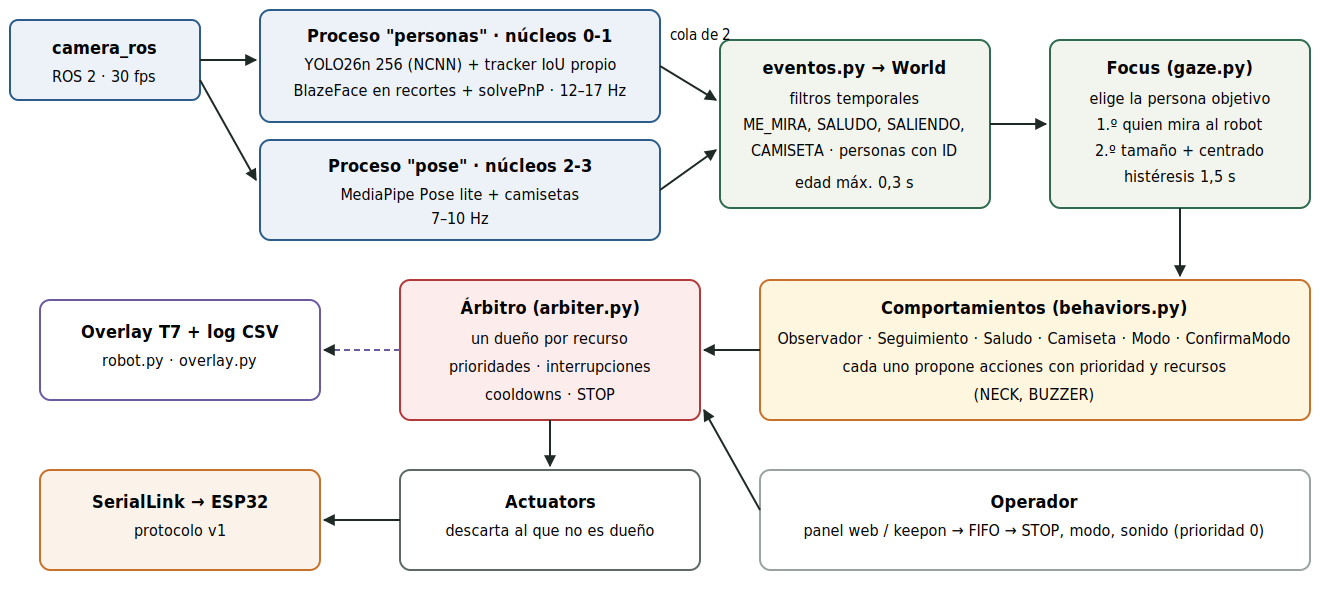<br><sub>Editable: <code>diagramas/08_arquitectura.drawio</code></sub>

*Figura 7. Flujo real de datos. Todo corre en la Pi en Python; ROS 2 solo entrega la imagen.*

| Módulo / archivo | Responsabilidad | Entradas | Salidas |
|---|---|---|---|
| Captura (`camera_ros`, `keepon/camera.py`) | Leer la cámara y entregar siempre el último cuadro | Sensor IMX708 | Imagen 640×480 con marca de tiempo |
| Percepción (`keepon/perception.py`, `tracker.py`) | Personas con ID, rostros y mirada, pose, camisetas | Último cuadro | Detecciones crudas por cuadro (cola de 2) |
| Modelo del mundo (`keepon/eventos.py`, `world.py`) | Filtros temporales y estado de cada persona | Detecciones crudas | Personas con ID y eventos activos, edad del dato |
| Foco de atención (`keepon/gaze.py`, `Focus`) | Elegir a quién mirar | Mundo | ID objetivo |
| Comportamientos (`keepon/behaviors.py`) | Proponer acciones con prioridad y recursos | Mundo, objetivo, modo | Propuestas |
| Árbitro (`keepon/arbiter.py`) | Asignar cuello y buzzer | Propuestas, STOP del operador | Dueño de cada recurso |
| Actuadores y comunicación (`actuators.py`, `link.py`, `protocol.py`, firmware) | Filtrar por dueño y mandar a la ESP32 | Órdenes del dueño | `J`, `S`, `STOP`… por serie |
| Monitoreo y log (`robot.py`, `overlay.py`) | Overlay en vivo y registro | Todo lo anterior | Video `/keepon/overlay`, `logs/run_*.csv` |

**Tasas y concurrencia:** cámara 30 fps; proceso de personas 12–17 Hz; proceso de pose 7–10 Hz; lazo de decisión y control 40 Hz (medido 36–39 Hz);
trayectorias en la ESP32 a 100 Hz. Los procesos de percepción mandan su resultado por colas de tamaño 2 que descartan lo viejo: nunca bloquean el lazo.
**Datos antiguos:** un mundo de más de 0,3 s se considera sin datos (cámara caída). **Recuperación:** la Pi detecta el reinicio de la ESP32
(`HELLO 0`) y resincroniza; la ESP32 frena sola si la Pi deja de hablar (watchdog de 500 ms). El operador entra por un FIFO (panel web o `keepon`)
con la prioridad más alta.

## 6. Control de mirada y foco de atención (T3 y T4)

### 6.1. Lazo de control visual

La referencia es el **centro óptico** de la cámara, que está en la nariz, entre los dos ojos. Para el rostro objetivo con centro (u, v) en píxeles:

$$e_{yaw} = \arctan\frac{u - c_x}{f_x} \qquad e_{pitch} = \arctan\frac{v - c_y}{f_y} - 8^\circ$$

Con fx ≈ 948 px, 1° ≈ 16,5 px. Los 8° (`mirar_abajo_deg`) hacen que la cámara apunte por debajo de la cara para que entre la camiseta.
Convención de signos: yaw + = derecha, pitch + = arriba (el signo de la imagen se corrige en cada eje).

**Modo actual, por objetivo (`gaze.modo: objetivo`):**

```
dirección = posición del cuello CUANDO SE SACÓ LA FOTO + error en la imagen
si el cuello estaba quieto al sacar la foto (< 1° del objetivo):
    si |dirección − referencia| > 2,5°:  referencia = dirección   (un solo movimiento rápido)
    si no:                               la referencia queda quieta
```

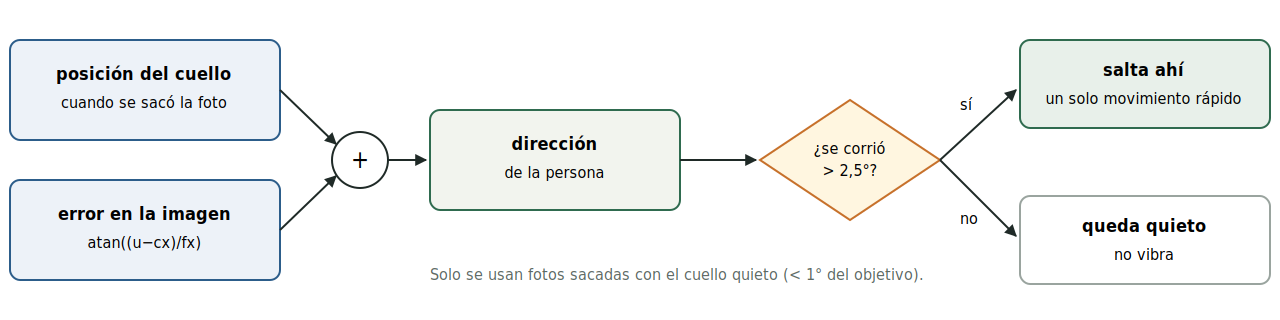<br><sub>Editable: <code>diagramas/09_mirada_por_objetivo.drawio</code></sub>

*Figura 8. Mirada por objetivo.* Usar la posición del cuello del momento de la foto compensa el atraso de la percepción (~100–135 ms): en
simulación, un salto a 25° con 150 ms de atraso pasó de sobrepasarse hasta 29° a llegar derecho a 25°, y los cambios de referencia bajaron de 25
a 0 con la persona quieta y de 300 a 29 con la persona caminando.

**Modo anterior, de respaldo (`gaze.modo: velocidad`), validado en el robot:** control proporcional en velocidad con zona muerta suave,
saturación y suavizado: `velocidad = kp × (|e| − zona muerta)` con kp = 4,0 (yaw) / 2,5 (pitch) 1/s, zona muerta 3 % de la imagen, saturación
150 / 90 °/s y suavizado EMA del error con α = 0,5 / 0,3. Se reemplazó porque hacía avanzar a los servos despacio y vibraban.

### 6.2. Selección del objetivo

1. **Prioridad estricta a quien mira al robot** (ME_MIRA activo).
2. **Si nadie lo mira:** puntaje = 0,6 × tamaño de la caja + 0,4 × cercanía al centro (la persona más cercana y central).
3. **Histéresis:** un candidato tiene que ser mejor durante **1,5 s seguidos** para quitarle el foco al actual; evita saltos constantes.

### 6.3. Pérdida y recuperación del objetivo

- **Pérdida < 1 s** (`lost_hold_s`): se mantiene la mirada donde estaba y el mismo objetivo; si reaparece, sigue sin cambios.
- **Pérdida prolongada:** se libera el objetivo; el Seguimiento deja de proponer y el árbitro le da el cuello al **Observador**, que arranca desde
  la postura actual (sin salto): primero sostiene la mirada donde estaba la persona, después centra la vista y explora (sección 7.1).
- **Reaparición:** el foco elige de nuevo según 6.2 y el Seguimiento interrumpe al Observador (prioridad 4 contra 5).

## 7. Comportamientos y personalidades (T5)

### 7.1. Comportamientos

| Comportamiento | Disparador real | Respuesta | Recursos usados | Duración / finalización | Evidencia |
|---|---|---|---|---|---|
| Observador (modo `exploracion`, Tabla 1) | No hay objetivo | Mira 1,5 s donde quedó la última persona, centra la vista (1,6 s, mínimo jerk) y barre ±45° sin pararse (25 °/s de media); cada 2 barridos, una sacada rápida a un punto de interés que fija 1,5 s con roll ±5° | Cuello | Continuo, mientras no haya objetivo | Robot (08/11; a 20 °/s el yaw vibraba, se subió a 25 °/s) |
| Seguimiento | Hay objetivo (foco) | Centra el rostro con yaw y pitch | Cuello | Continuo, mientras haya objetivo | Robot |
| Saludo | SALUDO de cualquier persona visible | 3 cabeceos de 12° (período 1 s) + R2D2 | Cuello + buzzer | ~3 s; cooldown 5 s por persona | Robot |
| Hincha de Olimpia | CAMISETA_OLIMPIA | Polca de Olimpia (7,1 s) **sin dejar de seguir** | Buzzer | Hasta el fin de la polca; **una vez por aparición** de cada persona | Robot (la vez por aparición, en tests) |
| Hincha de Cerro | CAMISETA_CERRO | Abucheo (2,5 s) | Buzzer | Hasta el fin del sonido; una vez por aparición | Robot |
| Curiosidad (extra) | Objetivo quieto 3 s | Inclina la cabeza 15° en roll durante 2 s, alternando el lado | Cuello (dentro del dueño) | 2 s; no repite antes de 8 s | Robot |
| Ejes (operador, para la demo) | Botón «Ejes» del panel o `keepon ejes` | Recorre yaw ±30°, pitch +20/−15° y roll ±15° (`ejes.secuencia`) y vuelve a HOME | Cuello | ~15 s; después retoma el Observador o el seguimiento | Tests; sin probar en el robot |

### 7.2. Modos de personalidad

| Modo | Evento disparador | Reacción | Condición de retorno | Comando y confirmación sonora |
|---|---|---|---|---|
| Tímido | ME_MIRA del objetivo | Aparta la mirada 25° al costado con más lugar, 12° abajo y 10° de roll; la sostiene 2,5 s | Vuelve a espiar en 3 s con una curva suave; no repite con esa persona antes de 3 s | `keepon t` / panel · BEEP_TIMIDO (0,35 s) |
| Atrevido | ME_MIRA del objetivo | Levanta el mentón 10°, 3 veces (período 1,2 s), siguiendo en yaw | Al terminar los 3,6 s vuelve al seguimiento; espera 3 s | `keepon a` / panel · BEEP_ATREVIDO (0,35 s) |
| Maleducado | Empieza un SALIENDO del objetivo | Silbido de piropo (1,2 s), convive con el seguimiento | Una vez por salida; como mucho uno cada 40 s entre todos | `keepon m` / panel · BEEP_MALEDUCADO (0,45 s) |
| Neutro (recomendado) | — | Solo sostiene el contacto visual (seguimiento). Es el modo inicial | — | `keepon n` / panel · BEEP_NEUTRO (0,25 s) |

### 7.3. Diagramas de estados

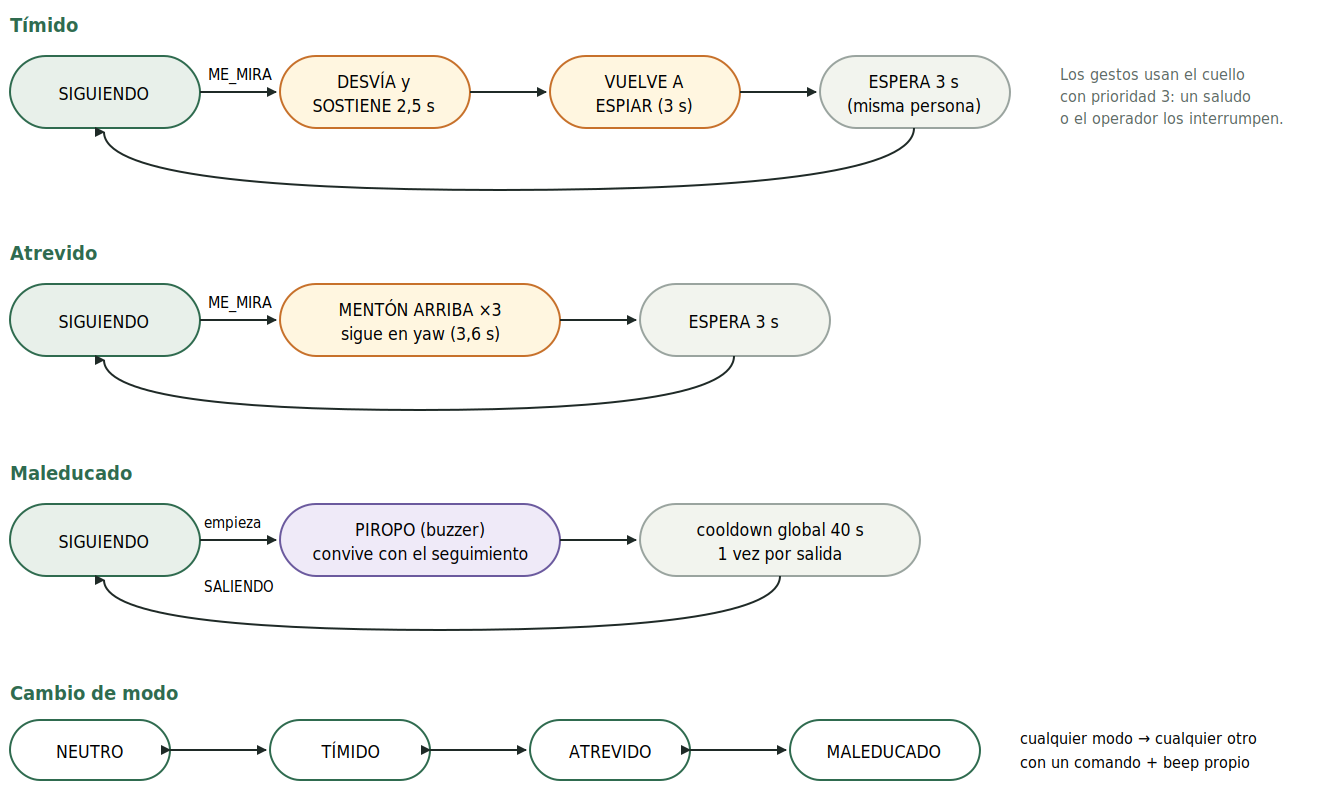<br><sub>Editable: <code>diagramas/10_estados_modos.drawio</code></sub>

*Figura 9. Diagramas de estados de Tímido, Atrevido y Maleducado, y cambio entre modos.* **Neutro** tiene un solo estado (SIGUIENDO / OBSERVANDO
según haya objetivo). Las esperas son cooldowns por persona (Tímido, Atrevido) o global (piropo).

**Cambio de modo en ejecución:** el operador manda el comando desde el panel del celular o con `keepon n|t|a|m`; la Pi cambia el modo al instante y
pide el beep de confirmación con prioridad de operador (solo el buzzer). Las reacciones de modo usan prioridad 3: si una reacción está en curso,
termina o la interrumpe un comportamiento más importante; el modo nuevo rige desde la próxima reacción. Limitación conocida: si en ese momento
suena otro sonido del operador, el beep se pierde.

### 7.4. Sonidos

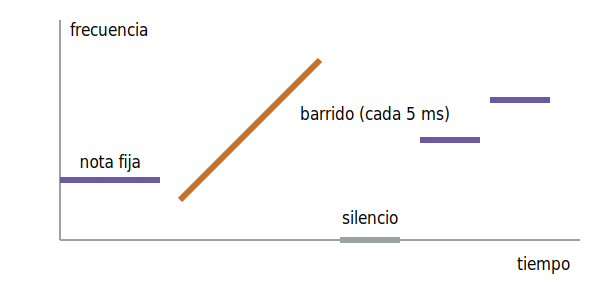<br><sub>Editable: <code>diagramas/11_segmentos_sonido.drawio</code></sub>

El buzzer **pasivo** suena a la frecuencia de la señal: la ESP32 la genera con un timer LEDC propio. Cada sonido es una tabla de segmentos
`{frecuencia inicial, frecuencia final, ms}`: nota fija, barrido lineal (la frecuencia se actualiza cada 5 ms) o silencio. Se reproduce por pasos
temporizados con `millis()`, **sin `delay()`**: la trayectoria y la comunicación siguen corriendo. El volumen se regula con el ciclo de trabajo
(50 % = máximo) y se cambia en ejecución con `VOL`.
**Polca:** fragmento de la polca del Club Olimpia transcrito a mano de la partitura: compases 1 a 8 en 6/8, negra con puntillo = 135, Fa mayor
(corchea de 148 ms, 7,104 s), una octava más arriba de lo escrito (659–1397 Hz) porque más abajo el buzzer suena débil; 15 ms de silencio entre notas.
Personalización: R2D2, abucheo, piropo, un beep distinto por modo y, como extra, un fragmento de la polca de Cerro.

### 7.5. Panel del celular (control del operador)

El operador maneja a Wall-E desde el teléfono con una **app web propia**: la Raspberry Pi la sirve en el puerto 8081
(`scripts/panel_web.py`, página en `scripts/panel/`) y se instala en el celular con "Agregar a pantalla de inicio". Cada
botón manda un comando que entra al robot por el mismo FIFO que `keepon`, con la **prioridad del operador (0)**: le gana a
cualquier comportamiento. El servidor solo acepta una lista cerrada de comandos, así que desde la página no se puede
ejecutar nada más en la Pi.

| Botón | Qué hace |
|---|---|
| Encender / Apagar | Arranca o apaga el robot entero (servicio `keepon`); Apagar lo lleva a HOME antes de soltar los servos |
| STOP | Detiene cuello y buzzer y queda enclavado hasta RESUME (tocarlo de nuevo) |
| Neutro / Tímido / Atrevido / Maleducado | Cambia el modo de personalidad al instante, con su beep de confirmación |
| Home / Resume | Home lleva la cabeza a 0°/0°/0° y la deja ahí; Resume libera STOP y HOME |
| Ejes | Demostración de los tres ejes (yaw, pitch y roll) en ~15 s, y vuelve |
| Sonidos y volumen | R2D2, polcas, abucheo, piropo y desaprobación; volumen 0–100 %, guardado para el próximo arranque |
| Estado | Modo, a quién sigue y si lo mira, dueño del cuello y del buzzer, ángulos, percepción y último comando (cada 1 s) |

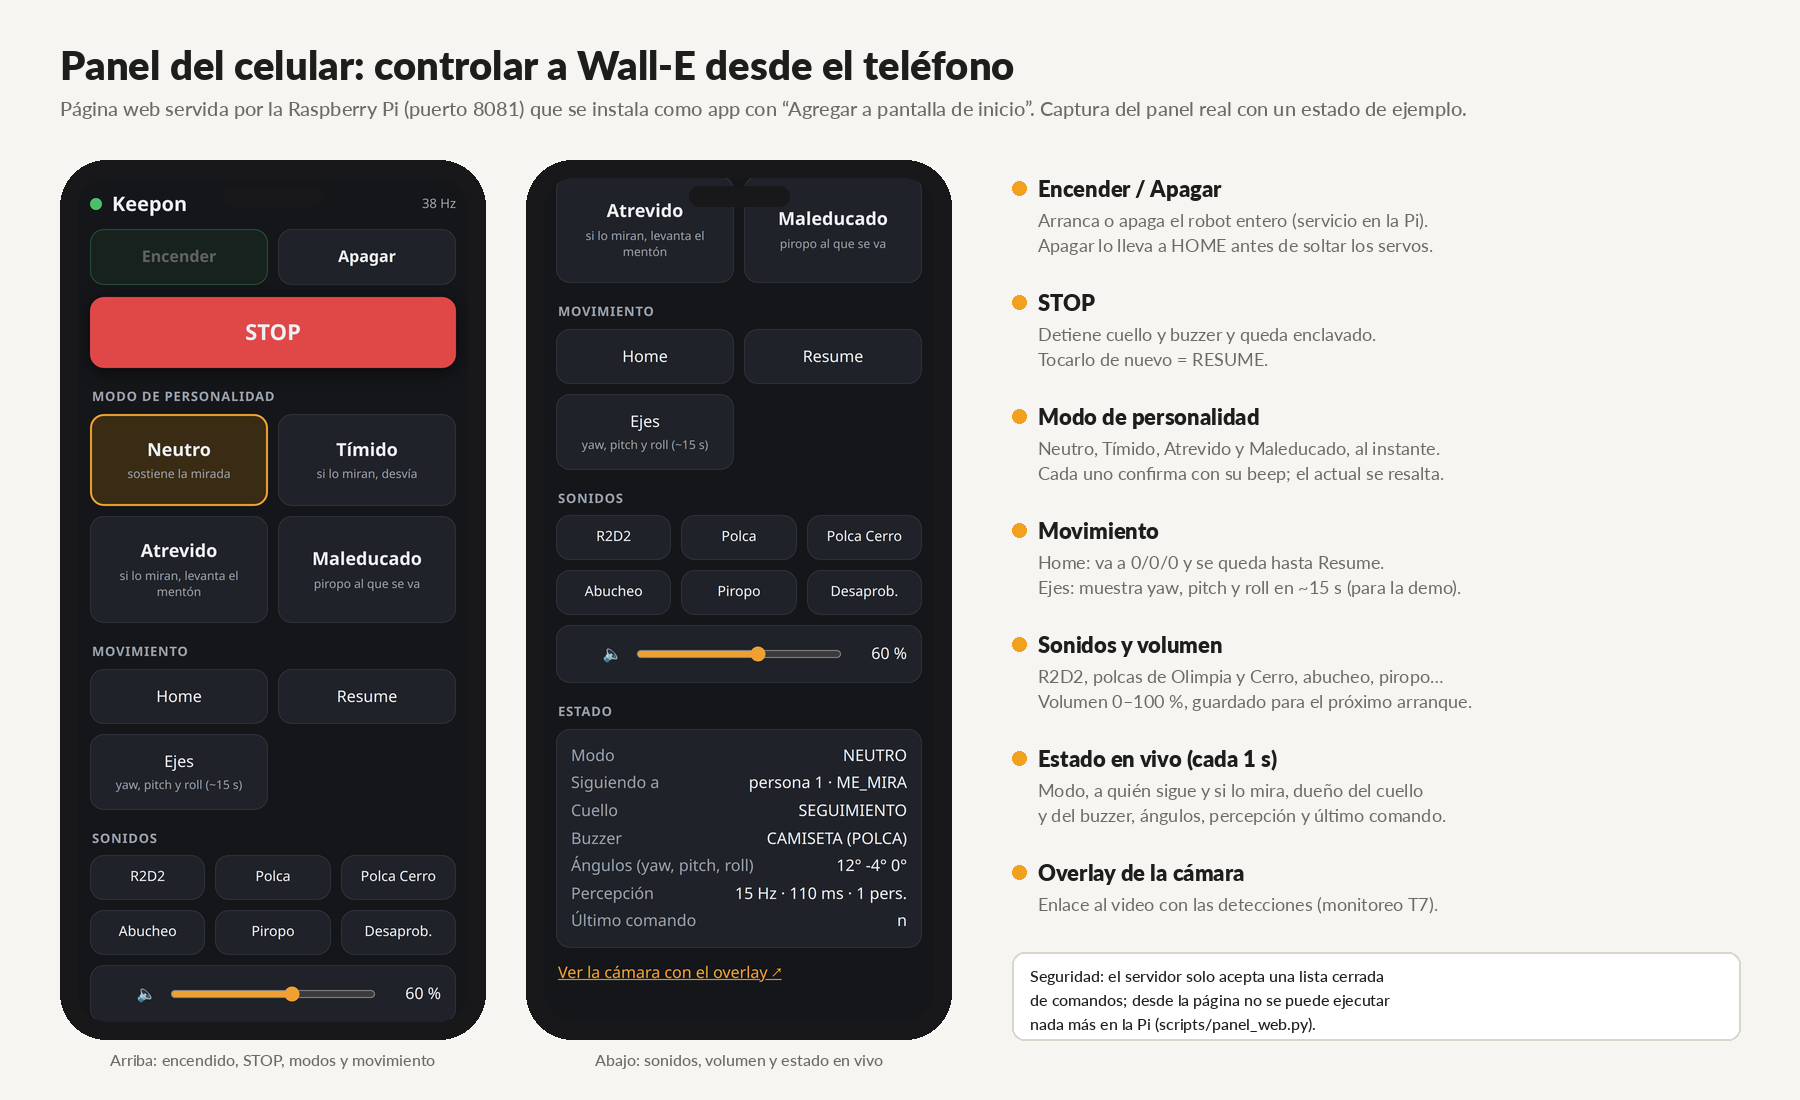

*Figura 9b. Panel del celular: captura de la app real (con un estado de ejemplo) y qué hace cada grupo de botones. Se
regenera con `scripts/captura_panel.py`.*

In [5]:
# Duración de cada sonido [s] (sounds de config.yaml; el firmware avisa DONE al terminar).
display(pd.DataFrame({"duración [s]": cfg["sounds"]}))

,duración [s]
R2D2,1.600
POLCA,7.104
POLCA_CERRO,6.000
ABUCHEO,2.500
PIROPO,1.200
DESAPROBACION,0.800
BEEP_NEUTRO,0.250
BEEP_TIMIDO,0.350
BEEP_ATREVIDO,0.350
BEEP_MALEDUCADO,0.450


## 8. Arbitraje, reactividad y robustez (T6)

### 8.1. Tabla de prioridades real

| Prioridad | Comportamiento / orden | Cuello | Buzzer | Interrumpible por | Condición de liberación |
|---|---|---|---|---|---|
| 0 | STOP / HOME / Ejes / operador | Sí (STOP, HOME, Ejes) | Sí (sonidos, beeps) | Nadie | STOP y HOME: hasta `RESUME`; Ejes: al terminar la secuencia; sonidos y beeps: al terminar |
| 1 | Saludo | Sí | Sí | Solo el operador | Fin de los cabeceos y del R2D2 |
| 2 | Camiseta | No | Sí | Operador o saludo | Fin de la polca o del abucheo |
| 3 | Reacción de personalidad | Sí (Tímido, Atrevido) | Sí (Maleducado) | Cualquiera más importante | Fin del gesto o del piropo |
| 4 | Seguimiento | Sí | No | Cualquiera más importante | Cuando deja de haber objetivo |
| 5 | Observador | Sí | No | Cualquiera más importante | Cuando aparece un objetivo |

In [6]:
# La misma tabla, leída de config.yaml (priorities y cooldowns).
display(pd.DataFrame({"prioridad": cfg["priorities"]}).sort_values("prioridad"))
display(pd.DataFrame({"segundos": {k: ("una vez por aparición" if v is None else v) for k, v in cfg["cooldowns"].items()}}))

,prioridad
OPERADOR,0
EJES,0
SALUDO,1
CAMISETA,2
MODO,3
SEGUIMIENTO,4
OBSERVADOR,5


,segundos
SALUDO_por_persona,5.0
CAMISETA_por_persona,una vez por aparición
PIROPO_global,40.0


### 8.2. Exclusión y coexistencia

El árbitro (`keepon/arbiter.py`, desarrollo propio) aplica estas reglas en cada ciclo de 25 ms:
1. **Exclusividad:** cada recurso (NECK, BUZZER) tiene a lo sumo un dueño.
2. **Prioridad:** una propuesta solo le quita un recurso a un dueño menos importante *y* que acepte ser interrumpido por ella.
3. **Atomicidad:** se conceden todos los recursos pedidos o ninguno; si a una acción le quitan un recurso, se cancela entera.
4. **Continuas y episódicas:** seguir y observar retienen el cuello mientras se vuelvan a proponer; saludo y polca, hasta que terminan.

Además, `Actuators` descarta cualquier orden de quien no es dueño del recurso: **nunca hay dos controladores escribiendo al cuello**. La
curiosidad y los gestos de los modos se calculan dentro del dueño del cuello, como una sola orden coherente.

**Polca + seguimiento:** usan recursos distintos (buzzer y cuello), así que conviven: el robot silba mientras sigue a la persona.
**Saludo durante otro sonido:** el saludo pide cuello + buzzer con prioridad 1; le quita el buzzer a la polca (prioridad 2, interrumpible por 1),
que se cancela, y el cuello al seguimiento. Al terminar el saludo, el seguimiento retoma el cuello.

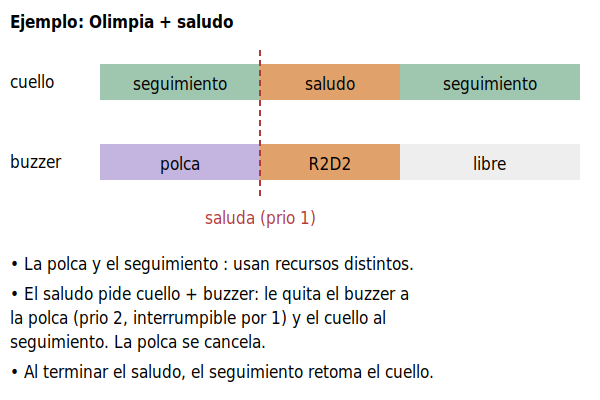<br><sub>Editable: <code>diagramas/12_conflicto_arbitro.drawio</code></sub>

### 8.3. Anti-repetición y anti-oscilación

- **Cooldowns** (cuentan desde que la acción empieza): saludo 5 s por persona, camiseta **una vez por aparición** de cada persona (por ID del tracker; antes 25 s, y con la camiseta a la
  vista la polca se repetía 4 veces en 90 s), piropo 40 s global; Tímido y Atrevido
  no repiten con la misma persona hasta terminar el gesto más 3 s; curiosidad, 8 s.
- **Gesto nuevo:** un saludo cuenta una sola vez; para otro, la mano tiene que bajar 0,4 s. El piropo se dispara en el **flanco** de SALIENDO
  (una vez por salida).
- **Filtros temporales e histéresis:** ME_MIRA 0,5 s / 0,3 s; camisetas 6 / 6 cuadros; SALIENDO 0,2 s / 0,6 s; foco 1,5 s para cambiar;
  retención de 1 s ante pérdida; la mirada no se mueve por desvíos menores a 2,5°.

### 8.4. No bloqueo, parada y recuperación

- **No bloqueo:** la percepción corre en procesos aparte con colas que descartan lo viejo; el lazo de la Pi nunca espera a la ESP32 (las órdenes son
  asíncronas y se confirman con `ACK`); la ESP32 ejecuta trayectorias y sonidos por pasos temporizados, sin `delay()`.
- **HOME del operador:** como STOP, detiene el árbitro, lleva la cabeza a 0/0/0 y la deja ahí hasta `RESUME` (antes los comportamientos la
  pisaban en el ciclo siguiente). Probado en el robot.
- **STOP:** la orden del operador cancela todas las acciones, incluso las no interrumpibles, y queda enclavada en la Pi y en la ESP32 hasta
  `RESUME`; si falla la transmisión se reintenta. Al apagar, el robot va a HOME.
- **Pérdida de comunicación:** watchdog de 500 ms en la ESP32 (frena y mantiene la postura sin soltar los servos); reinicio de la ESP32 detectado
  con `HELLO 0` y resincronización.
- **Vuelta suave:** al terminar o interrumpirse una acción, el comportamiento continuo correspondiente (seguimiento u observador) arranca desde
  la postura actual y la ESP32 respeta `vmax`/`amax` con la curva S, así que no hay saltos.

## 9. Parámetros de la versión entregada

Valores de `config.yaml` de la versión indicada en la portada (la celda de abajo los lee directamente del archivo).

| Grupo | Parámetro | Valor | Unidad | Justificación / método de ajuste |
|---|---|---|---|---|
| Control | Ganancias yaw / pitch (modo velocidad, respaldo) | 4,0 / 2,5 | 1/s | Ajuste en el robot; bajarlas empeoró la vibración |
| Control | Umbral de la mirada por objetivo (modo actual) | 2,5 / 2,5 | ° | Menos que esto no justifica un movimiento (evita vibrar) |
| Control | Zona muerta (modo velocidad) | 0,03 | fracción de la imagen | Mayor dejaba la cara a 1,5–3° del centro |
| Control | Suavizado EMA del error yaw / pitch | 0,5 / 0,3 | — (1 = sin filtro) | Ajuste en el robot (05/11) |
| Control | vmax / amax del cuello (yaw, pitch, roll) | 180/120/250 · 600/400/900 | °/s · °/s² | Movimientos rápidos y pocos: lentos hacían vibrar a los servos (roll en prueba) |
| Control | Curva S `suavizado_s` (yaw, pitch, roll) | 0,10 / 0,10 / 0,15 | s | Jerk del yaw ≤ 12 000 °/s³; sin ella el roll vibraba más |
| Observador | Exploración: amplitud, velocidad media, fijación, sacada | ±45° · 25 °/s · 1,5 s · cada 2 barridos | ° · °/s · s | A 20 °/s el yaw vibraba barriendo (robot, 08/11) |
| Foco | Tiempo para cambiar objetivo | 1,5 | s | Evita saltos entre personas parecidas |
| Foco | Tiempo de retención por pérdida | 1,0 | s | Pedido por la consigna (< 1 s: mantener) |
| Eventos | Confianza y filtros por evento | YOLO ≥ 0,4 · ME_MIRA < 15°, 0,5 / 0,3 s · SALUDO 2 ciclos en 2,5 s · camisetas 6 / 6 cuadros · SALIENDO 0,2 / 0,6 s | — | Medidos con las prendas y gestos reales; `looking_deg` sin validar con varias personas |
| Arbitraje | Cooldowns por persona / globales | Saludo 5 (por persona) · camiseta una vez por aparición · piropo 40 (global) | s | Cada 25 s la polca se repetía con la camiseta a la vista; piropo cada 40 s como sugiere la consigna |
| Ejecución | Tasas de percepción y control | Personas 12–17 · pose 7–10 · lazo 40 (36–39 medido) · ESP32 100 | Hz | Medido en la Pi con el robot completo |
| Comunicación | Timeout / watchdog | Watchdog 500 · keepalive 200 · mundo viejo 300 | ms | Frena si la Pi deja de hablar; descarta datos de cámara caída |
| Sonido | Frecuencias y tiempos | Polca 659–1397 Hz, corchea 148 ms, 7,104 s · barridos cada 5 ms · volumen 0,12 (6 % de ciclo de trabajo) | Hz / ms | Octava alta: abajo el buzzer suena débil |

In [7]:
def tabla(seccion, claves=None):
    d = cfg[seccion]
    return pd.DataFrame({"valor": {k: (str(v) if isinstance(v, (list, dict)) else v)
                                   for k, v in d.items() if claves is None or k in claves}})

print("Cuello"); display(tabla("neck", ["limits", "home", "vmax", "amax", "suavizado_s"]))
print("Observador (modo", cfg["observer"]["modo"] + ")"); display(tabla("observer", ["modo"]).T)
display(pd.DataFrame({"valor": {k: str(v) for k, v in cfg["observer"]["exploracion"].items()}}))
print("Demostración de los ejes"); display(tabla("ejes"))
print("Mirada (gaze)"); display(tabla("gaze"))
print("Foco de atención (focus)"); display(tabla("focus"))
print("Percepción"); display(tabla("perception", ["yolo_imgsz", "yolo_conf", "face_crop_px", "looking_deg", "max_age_s", "pose_max_hz"]))
print("Eventos"); display(tabla("eventos"))

Cuello


,valor
limits,"{'yaw': [-70.0, 70.0], 'pitch': [-20.0, 30.0], 'roll': [-20.0, 20.0]}"
home,"[0.0, 0.0, 0.0]"
vmax,"[180.0, 120.0, 250.0]"
amax,"[600.0, 400.0, 900.0]"
suavizado_s,"[0.1, 0.1, 0.15]"


Observador (modo exploracion)


,modo
valor,exploracion


,valor
fijacion_s,1.5
centrar_s,1.6
pausa_centro_s,1.0
amp_deg,45.0
vel_barrido,25.0
pitch_barrido,0.0
sacada_cada,2
puntos_interes,"[[-20.0, 6.0, 5.0], [30.0, -4.0, -5.0], [5.0, 10.0, 0.0]]"


Demostración de los ejes


... (5 outputs left out)

Percepción


,valor
max_age_s,0.3
yolo_imgsz,256.0
yolo_conf,0.4
face_crop_px,192.0
pose_max_hz,30.0
looking_deg,15.0


Eventos


,valor
mira_sostenida_s,0.50
mira_suelta_s,0.30
saludo_ciclos,2.00
saludo_ventana_s,2.50
saludo_amp_hombros,0.25
saludo_margen_hombros,0.10
saludo_mano_abajo_s,0.40
pose_vis_min,0.50
saliendo_borde_frac,0.15
saliendo_vel_px_s,80.00


In [8]:
print("Modos de personalidad"); display(pd.json_normalize(cfg["modos"], sep=".").T.rename(columns={0: "valor"}))
print("Saludo"); display(tabla("greeting"))
print("Curiosidad"); display(tabla("curiosidad"))
print("Detector de camisetas"); display(tabla("camiseta"))
print("Comunicación"); display(tabla("serial", ["baud", "watchdog_ms", "keepalive_ms"]))

Modos de personalidad


,valor
inicial,NEUTRO
timido.desvio_yaw_deg,25.0
timido.desvio_pitch_deg,12.0
timido.desvio_roll_deg,10.0
timido.sostener_s,2.5
timido.regreso_s,3.0
timido.espera_s,3.0
atrevido.menton_deg,10.0
atrevido.periodo_s,1.2
atrevido.veces,3


Saludo


,valor
nods,3.0
nod_amp,12.0
nod_period_s,1.0


Curiosidad


,valor
activa,True
quieto_s,3.0
movimiento_max_deg,5.0
amp_deg,15.0
sostener_s,2.0
espera_s,8.0


Detector de camisetas


,valor
vis_min,0.5
ancho_min_px,40
margen_lados,0.1
desde_hombros,0.15
hasta_hombros,1.1
visible_min,0.4
rojo,"{'h_max': 8, 'h_min': 165, 's_min': 120, 'v_min': 60}"
azul,"{'h_min': 100, 'h_max': 160, 's_min': 25, 'v_min': 15, 'v_max': 130}"
columnas,8
col_dominante,0.5


Comunicación


,valor
baud,115200
watchdog_ms,500
keepalive_ms,200


## 10. Monitoreo y registros (T7)

El overlay se ve en un navegador en `http://<ip-de-la-pi>:8080/stream_viewer?topic=/keepon/overlay` y muestra: personas con su caja e ID,
el objetivo resaltado con el ángulo de su mirada (`angulo N`) y el torso evaluado, los eventos activos de cada persona, el modo actual, el dueño
del CUELLO y del BUZZER y los ángulos comandados (yaw, pitch, roll).

**[Completar]** Insertar captura del video con overlay (con el consentimiento de quien aparezca).

**Formato de registro:** CSV con dos columnas, `t` (segundos) y `evento` (texto de la transición: arranque y fin de cada acción con su dueño
y motivo, cambios de foco, eventos, comandos del operador, líneas ESTADO periódicas con frecuencias y edad del cuadro).
**Ubicación de logs de la prueba:** `~/keepon/logs/run_AAAAMMDD_HHMMSS.csv` en la Pi (uno por corrida; `keepon log` lo sigue en vivo).
**Referencia temporal utilizada:** segundos desde el arranque del robot (reloj monotónico de la Pi); en la simulación, tiempo simulado.

Fragmento real del escenario simulado de 30 s (la celda de abajo lo vuelve a generar), con un conflicto resuelto:

| Tiempo | Evento / transición | Objetivo | Modo | Dueño del cuello | Dueño del buzzer | Ángulos comandados |
|---|---|---|---|---|---|---|
| 11,05 s | `ARB start SEGUIMIENTO#4 persona=1` | 1 | Neutro | SEGUIMIENTO | — | siguiendo a la persona 1 |
| 11,50 s | `ARB start CAMISETA#5 persona=1` | 1 | Neutro | SEGUIMIENTO | CAMISETA (polca) | siguiendo |
| 13,50 s | `ARB stop SEGUIMIENTO#4 (interrumpido por SALUDO)` · `ARB stop CAMISETA#5 (interrumpido por SALUDO)` · `ARB start SALUDO#6` | 1 | Neutro | SALUDO | SALUDO (R2D2) | cabeceos de 12° en pitch |
| 16,52 s | `ARB stop SALUDO#6 (fin)` | 1 | Neutro | — | — | — |
| 16,55 s | `ARB start CAMISETA#7 persona=2` · `ARB start SEGUIMIENTO#8 persona=1` | 1 | Neutro | SEGUIMIENTO | CAMISETA | siguiendo |
| 22,02 s | `OPERADOR STOP` · `ARB stop SEGUIMIENTO#8 (STOP)` | 2 | Neutro | — (STOP) | — | frena y mantiene |

**Conflicto resuelto:** a los 11,5 s la persona 1 lleva la camiseta de Olimpia y el robot silba la polca mientras la sigue (cuello y buzzer con
dueños distintos). A los 13,5 s esa persona saluda: el saludo (prioridad 1) pide los dos recursos, interrumpe a la polca (prioridad 2) y al
seguimiento (prioridad 4), hace los cabeceos con el R2D2 y, al terminar, el seguimiento retoma el cuello. A los 22 s el STOP del operador
cancela todo hasta el RESUME.

[   0.03] ESP32 sesión abierta fw=2
[   0.03] ARB start OBSERVADOR#1 persona=None recursos=NECK
[   4.98] FOCO None -> 1
[   4.98] ARB stop  OBSERVADOR#1 (interrumpido por SEGUIMIENTO)
[   4.98] ARB start SEGUIMIENTO#2 persona=1 recursos=NECK
[   8.00] ARB stop  SEGUIMIENTO#2 (interrumpido por SALUDO)
[   8.00] ARB start SALUDO#3 persona=1 recursos=BUZZER+NECK
[  11.02] ARB stop  SALUDO#3 (fin)
[  11.05] ARB start SEGUIMIENTO#4 persona=1 recursos=NECK
[  11.50] ARB start CAMISETA#5 persona=1 recursos=BUZZER
[  13.50] ARB stop  CAMISETA#5 (interrumpido por SALUDO)
[  13.50] ARB stop  SEGUIMIENTO#4 (interrumpido por SALUDO)
[  13.50] ARB start SALUDO#6 persona=1 recursos=BUZZER+NECK
[  16.52] ARB stop  SALUDO#6 (fin)
[  16.55] ARB start CAMISETA#7 persona=2 recursos=BUZZER
[  16.55] ARB start SEGUIMIENTO#8 persona=1 recursos=NECK
[  18.00] FOCO 1 -> 2
[  18.00] ARB retarget SEGUIMIENTO#8 persona 1 -> 2
[  19.05] ARB stop  CAMISETA#7 (fin)
[  21.02] CURIOSIDAD persona=2 inclina roll +15°


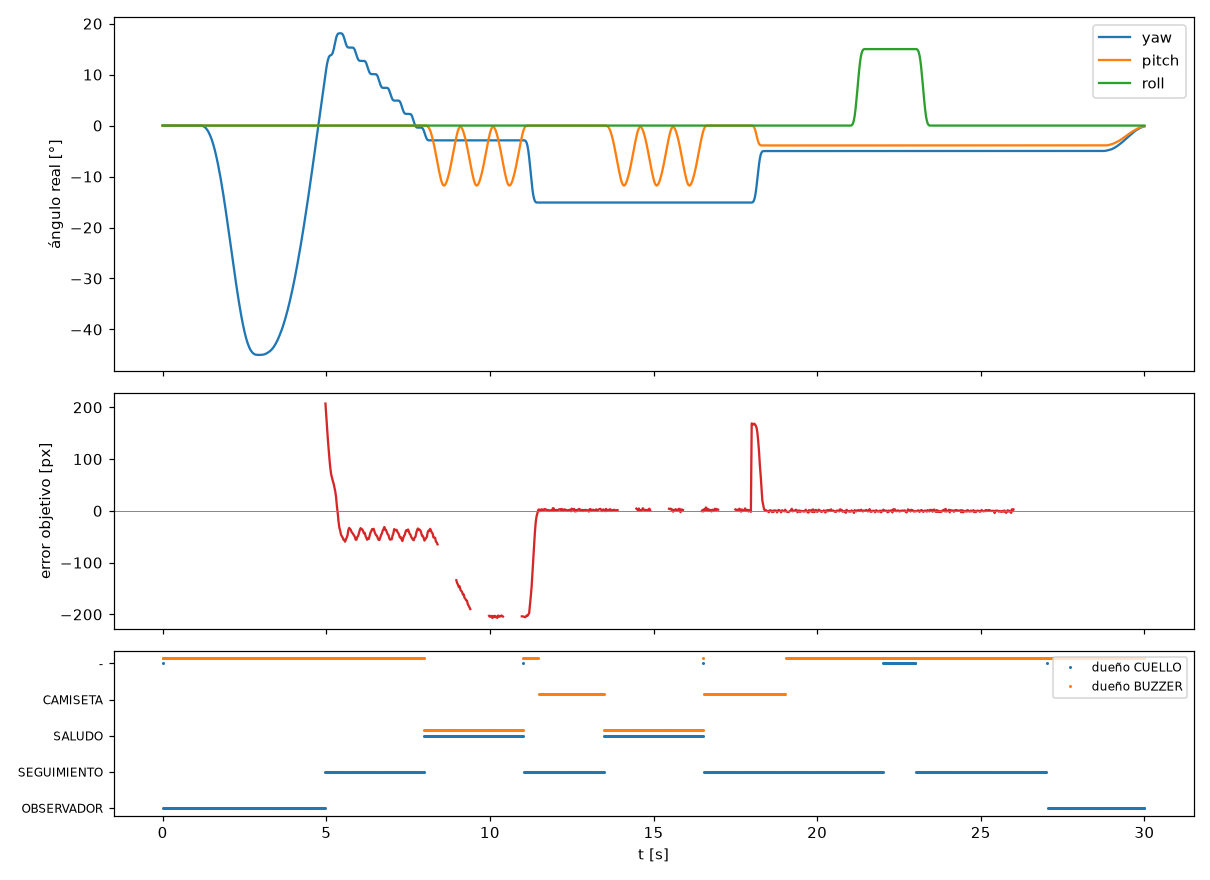

In [9]:
# Escenario simulado de 30 s del repositorio: árbitro, comportamientos y control reales contra la ESP32 simulada,
# con personas sintéticas. Imprime el log de transiciones y grafica ángulos y dueños de cada recurso.
import subprocess
from IPython.display import Image as Imagen
r = subprocess.run([sys.executable, "keepon-pro/scripts/sim_scenario.py", "--plot"], capture_output=True, text=True)
print(r.stdout.split("gráfico:")[0])
display(Imagen("keepon-pro/logs/sim_scenario.png"))

## 11. Pruebas y resultados

### 11.1. Protocolo de validación

**Fecha y versión probada:** robot completo 03/11–08/11/2026 (camisetas 04/11; curva S, roll, Observador y HOME 08/11), versión `v1.0-entrega`; firmware FW_VERSION 2.
**Equipo de procesamiento:** Raspberry Pi 5 (4 GB), Ubuntu 24.04 + ROS 2 Jazzy.
**Iluminación, distancias y cantidad de personas:** laboratorio con luz LED; 1,2 / 1,8 / 2,5 m; 1–2 personas (integrantes).
**Número de repeticiones por ensayo:** camisetas: tomas de 60 s por prenda; ESP32: 30 pruebas automáticas, 50 PING; simulación: escenario de 30 s determinista. En el robot completo, cada función se probó en la secuencia de 8 pruebas del video (sección 13), sin un conteo formal de repeticiones por función.

| Prueba | Procedimiento y criterio de aceptación | Resultado medido | Entorno (simulación / banco / robot) | Evidencia |
|---|---|---|---|---|
| HOME, límites y suavidad | Ir a HOME y a los extremos; sin choques; sin golpes | HOME y límites OK; roll limitado a ±20° (a +30° toca); signo del roll corregido el 08/11; vibración al moverse despacio y del roll girando a la derecha en la zona negativa | Robot | `config.yaml` (notas de calibración), `docs/BITACORA.md` 03/11, 05/11 y 08/11 |
| Curva S | Comparar el perfil con y sin curva S paso a paso, en Python y en el firmware | Jerk del yaw de 60 000–104 000 a ≤ 12 000 °/s³; nunca pasa vmax, amax ni el objetivo; +0,1 s por movimiento | Simulación / tests de conformidad del firmware | `tests/test_trajectory.py` |
| Observador «exploracion» | Sin personas: centra, barre, sacadas con roll | Hace la secuencia; a 20 °/s de media el yaw vibraba, se pasó a 25 °/s | Robot / tests | `tests/test_observador_exploracion.py` |
| HOME del operador | Botón Home con el Observador o el seguimiento activos | Va a 0/0/0 y queda hasta RESUME | Robot / tests | `tests/test_home_operador.py` |
| Polca una vez y Ejes | Camiseta a la vista 90 s; botón Ejes | Una polca por aparición (antes 4 en 90 s); Ejes recorre los 3 ejes y vuelve | Tests (sin probar en el robot) | `tests/test_polca_una_vez.py`, `tests/test_demo_ejes.py` |
| Detección y tracking por ID | 2 personas a 1,5 m; ID estable | 2 de 2 personas en el 100 % de los cuadros; rostro en el 80 % de las detecciones | Robot (Pi) | `docs/ESTADO_PI.md`, CSV de benchmarks |
| ME_MIRA y SALUDO | Mirar / no mirar; saludar con la mano | SALUDO responde con cabeceos + R2D2. ME_MIRA: mediana 8°, 30 de 42 lecturas bajo 15°, casi no se activaba | Robot | `docs/BITACORA.md` 03–05/11 |
| Camisetas Olimpia / Cerro | Tomas de 60 s a 3 distancias; detectada tras el filtro | Olimpia 82 % (99 % desde los 10 s); Cerro 98 % | Robot (cámara del robot) | `pruebas_camisetas/README.md` |
| Prendas lisas y falsos positivos | Remeras lisas roja y azul marino | 0 % de falsos positivos; blanca lisa solo sintética | Robot / simulación (blanca) | `pruebas_camisetas/README.md`, `tests/test_camiseta.py` |
| Seguimiento quieto / en movimiento | Persona quieta y caminando; cara centrada sin oscilar | Sigue (modo velocidad, con vibración). Modo objetivo: 0 cambios de referencia quieta, 29 caminando | Robot / simulación | `tests/test_mirada_objetivo.py` |
| Selección entre varias personas | Prioridad a quien mira; histéresis 1,5 s | Correcto en tests y simulación; con dos personas reales, escena 0:30–0:55 del video (no medido en el robot de forma cuantitativa) | Simulación / video | `tests/test_regresiones_codex.py`, `tests/test_scenario.py` |
| Pérdida breve / prolongada | Ocultar el objetivo < 1 s y > 1 s | Mantiene < 1 s; libera y pasa al Observador después | Simulación / robot | `tests/test_scenario.py` |
| Saludo + camiseta simultáneos | Saludar con la polca sonando | El saludo interrumpe la polca y la retoma el seguimiento; 0 violaciones | Simulación | Escenario de 30 s (sección 10) |
| Polca + seguimiento | Olimpia frente al robot | Silba mientras sigue | Robot | `docs/ESTADO.md` |
| Personalidades y cambio de modo | Cambiar de modo con sonido sonando; reacciones | Cambio + beep OK en el robot; Tímido no desviaba (ME_MIRA); Atrevido y Maleducado en simulación | Robot / simulación | `tests/`, `docs/PENDIENTES.md` |
| SALIENDO y anti-repetición | Salir del campo visual en Maleducado | Un piropo por salida, cooldown 40 s | Simulación | `tests/` |
| STOP durante movimiento y sonido | STOP con el cuello moviéndose y la polca sonando | Frena, corta el sonido, enclavado hasta RESUME | Simulación y ESP32 real; en el robot completo, escena 2:40–3:00 del video | `tests/test_regresiones_codex.py`, `scripts/prueba_firmware_real.py` |
| Recuperación tras interrupción | Reinicio de la ESP32; watchdog | Resincroniza; 6 min de robot real sin watchdogs falsos | Robot | `docs/BITACORA.md` 03/11 |
| Monitoreo y log | Overlay y CSV durante una corrida | Overlay con todos los campos; log CSV por corrida | Robot | `keepon/overlay.py`, `logs/` |

### 11.2. Rendimiento

| Métrica | Método de medición | Personas / carga | Duración / muestras | Resultado | Referencia de la consigna |
|---|---|---|---|---|---|
| Frecuencia de percepción | Línea ESTADO del log (contadores por proceso) | 1–2 personas, robot completo | Corridas de varios minutos | Personas 12–17 Hz · pose 7–10 Hz | ≥10 Hz |
| Latencia evento → inicio de respuesta | Estimada: edad del cuadro (96–135 ms) + ciclo del lazo (25 ms) + serie (4,4 ms) | 1 persona | — | ≈ 130–170 ms (estimación; la medición de punta a punta quedó como no medido en el robot) | ≤300 ms orientativo |
| Estabilidad / error de mirada | Error del objetivo en el escenario simulado (cámara sintética con ruido de 1,5 px) | 1–2 personas sintéticas | 30 s | Persona quieta: error ≈ 0 px (dentro del ruido). En el robot: no medido en el robot | Criterio propio documentado |
| Falsos positivos de camisetas | Tomas de 60 s con la cámara del robot | 1 persona | 4 tomas de 60 s | Roja lisa 0 %, azul marino lisa 0 % | Rechazar prendas lisas |

La latencia del enlace serie (4,4 ms) por sí sola no mide el lazo visual completo: la estimación suma desde que se toma la imagen hasta que la
ESP32 recibe la orden; el movimiento empieza en el siguiente paso de 10 ms. La medición propuesta es SALUDO → R2D2 con las marcas de tiempo del log.

,escena,configuración,imgsz,yolo_ms,face_ms,pose_ms,Hz,edad [ms],CPU [%]
0,sin personas,A_yolo480_t4,480,79.0,0.0,0.0,11.2,109.8,283
1,sin personas,A_yolo480_t2,480,88.6,0.0,0.0,10.6,126.3,252
2,sin personas,A_yolo320_t4,320,31.7,0.0,0.0,22.5,50.1,251
3,sin personas,A_yolo320_t2,320,45.4,0.0,0.0,17.3,67.6,223
4,sin personas,A_yolo256_t4,256,18.2,0.0,0.0,29.9,33.8,201
5,sin personas,A_yolo256_t2,256,36.0,0.0,0.0,17.1,54.1,177
6,sin personas,B_mediapipe,320,0.0,5.7,32.6,25.7,67.9,126
7,sin personas,C_full320_t2,320,49.5,6.0,34.2,11.1,122.2,202
8,sin personas,C_full320_t3,320,49.0,6.0,34.6,11.1,120.9,213
9,sin personas,C_full256_t2,256,34.2,6.0,33.8,13.4,105.0,185


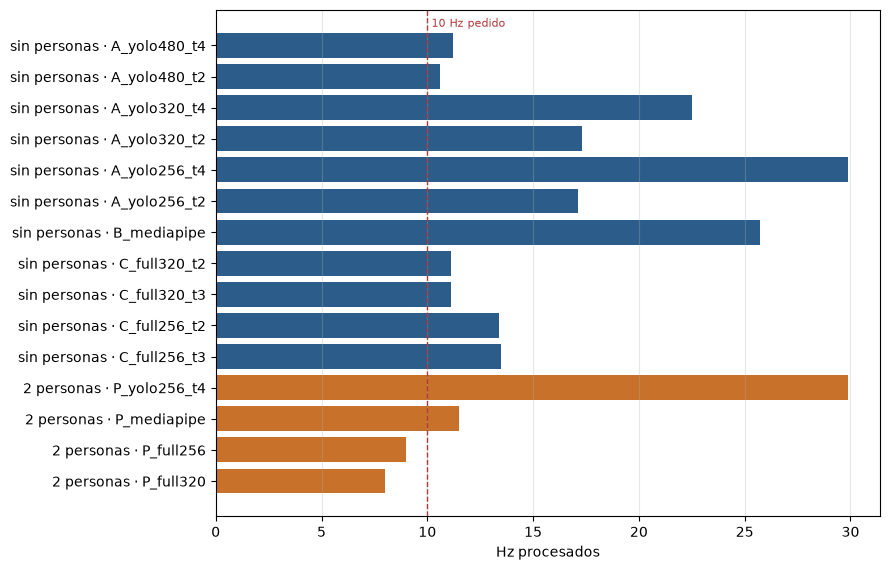

In [10]:
# Benchmarks de la percepción medidos en la Pi el 30/09 (antes de paralelizar): con todo en serie no se llegaba a 10 Hz.
b0 = pd.read_csv("keepon-pro/docs/benchmark_pi_20260930_sin_personas.csv"); b0["escena"] = "sin personas"
b2 = pd.read_csv("keepon-pro/docs/benchmark_pi_20260930_2personas.csv"); b2["escena"] = "2 personas"
b = pd.concat([b0, b2])
display(b[["escena", "label", "imgsz", "yolo_ms", "face_ms", "pose_ms", "proc_hz", "edad_ms", "cpu_pct"]]
        .rename(columns={"label": "configuración", "proc_hz": "Hz", "edad_ms": "edad [ms]", "cpu_pct": "CPU [%]"}))
fig, ax = plt.subplots(figsize=(9, 0.32 * len(b) + 1))
ax.barh([f"{e} · {l}" for e, l in zip(b["escena"], b["label"])], b["proc_hz"],
        color=["#2c5d8a" if e == "sin personas" else "#c7712b" for e in b["escena"]])
ax.axvline(10, color="#b23a3a", ls="--", lw=1); ax.text(10.2, -0.6, "10 Hz pedido", color="#b23a3a", fontsize=8)
ax.set_xlabel("Hz procesados"); ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

### 11.3. Discusión

**Qué funcionó.** La arquitectura de dos procesos permitió pasar de 9 Hz (todo en serie, 2 personas) a 12–17 Hz en la detección de personas.
El árbitro resolvió todos los conflictos sin violaciones y permitió que polca y seguimiento convivan. Escribir primero el robot completo contra
una ESP32 simulada, y el firmware como copia verificada por tests, hizo que la integración con el hardware fuera rápida: el firmware anduvo
30/30 en la primera prueba real. El detector de camisetas por reglas funcionó con las prendas reales y no dio falsos positivos con las lisas.

**Dónde falló y por qué.** (1) **ME_MIRA** casi no se activaba: la cámara no está calibrada (intrínsecos de otra cámara, centro supuesto) y el
umbral de 15° no se validó con varias personas; de ahí que Tímido no reaccionara. (2) **Vibración de los servos** al moverse despacio, por su
banda muerta: bajar velocidades y ganancias lo empeoró; se cambió a la mirada por objetivo (movimientos rápidos y pocos) y, el 08/11, a la curva S en
todos los movimientos (en el roll, sin curva S vibraba más). El roll sigue vibrando al girar a la derecha en la zona negativa con cualquier perfil:
probablemente el servo o la carga. (3) **Buzzer intermitente:** un cable jumper con falso contacto por el cuello. (4) El GPIO10 dejó de sonar con la cabeza armada: se pasó al GPIO5.
(5) El firmware daba watchdogs falsos por restar tiempos sin signo: se corrigió y quedó como test de regresión.

**Limitaciones que permanecen.** Cámara sin calibrar; Barcelona se confunde con Cerro; la pose queda en 7–10 Hz; la latencia de punta a punta no
está medida; la vibración del roll al girar a la derecha en la zona negativa; los modos Tímido, Atrevido y Maleducado y la demostración de
los ejes faltan probarlos en el robot.

## 12. Instalación, ejecución y reproducción

**Repositorio y versión:** https://github.com/HecVelaz/keepon-pro, versión `v1.0-entrega` (rama `main`, 08/11/2026; PR #3 a #7 integrados).
**Archivo ZIP de entrega:** [https://github.com/HecVelaz/keepon-pro/archive/refs/tags/v1.0-entrega.zip](https://github.com/HecVelaz/keepon-pro/archive/refs/tags/v1.0-entrega.zip) (release «Entrega final»: [https://github.com/HecVelaz/keepon-pro/releases/tag/v1.0-entrega](https://github.com/HecVelaz/keepon-pro/releases/tag/v1.0-entrega))
**README:** https://github.com/HecVelaz/keepon-pro/blob/main/README.md

1. **Hardware y sistema:** Raspberry Pi 5 (4 GB) con Ubuntu 24.04 + ROS 2 Jazzy y `camera_ros`; Camera Module 3 NoIR; ESP32-C3-DevKitM-1;
   servos RDS3218 + 2 × MG996R; buzzer pasivo; fuente de 6 V (4–5 A) y powerbank de 5 V / 3 A.
2. **Dependencias:** entorno `~/keepon_env` creado con `python3 -m venv --system-site-packages` (para ver `rclpy`) e instalar `requirements.txt`
   (versiones fijadas: numpy, pyyaml, pyserial, opencv, mediapipe 1.0.1, ultralytics, ncnn). `sudo usermod -aG dialout $USER` para el puerto serie.
3. **Modelos:** YOLO26n de Ultralytics, exportado a NCNN de 256 px con `python scripts/export_yolo.py yolo26n.pt 256` (queda en `models/`);
   los modelos de MediaPipe se descargan con la librería.
4. **Configuración y firmware:** todos los parámetros en `config.yaml` (`config.local.yaml` por máquina). Firmware: `bash scripts/cargar_firmware.sh`
   (genera `generado.h` desde `config.yaml`, compila y carga), sosteniendo la cabeza.
5. **Inicio y monitoreo:** encender powerbank y luego 6 V; `bash ~/keepon/scripts/keepon arrancar` o el botón Encender del panel
   (`http://<ip-de-la-pi>:8081`); overlay en `http://<ip-de-la-pi>:8080/stream_viewer?topic=/keepon/overlay`.
6. **Personalidad, STOP y apagado:** `keepon n | t | a | m`; `keepon stop` / `keepon resume` / `keepon home` (queda en HOME hasta `resume`); `keepon ejes` (demostración de los 3 ejes); `keepon parar` (vuelve a HOME) y después cortar los 6 V.

**Qué se reproduce sin el robot:** en Colab o en una PC, los tests (`pytest`, 257; los del firmware necesitan `g++`), el escenario simulado
(`python scripts/sim_scenario.py --plot`) y todas las celdas de este informe. **Requiere el robot:** la percepción con la cámara, el firmware en la
ESP32 y los movimientos y sonidos reales.

## 13. Video y secuencia de demostración

**Enlace al video:** [https://youtu.be/raOJljv1mVU](https://youtu.be/raOJljv1mVU) (también se reproduce en la celda de video del principio)
**Duración:** 3 minutos, con las 8 pruebas

Secuencia del video (8 pruebas, 3 minutos):

| Intervalo del video | Prueba | Evidencia observable |
|---|---|---|
| 0:00–0:15 | Robot completo y movimiento de los tres ejes (botón «Ejes» del panel) | Recorre yaw, pitch y roll y vuelve a HOME |
| 0:15–0:30 | Observador: sin personas, explora la escena | Centra la vista, barre suavemente y hace sacadas con roll |
| 0:30–0:55 | Seguimiento de una persona en movimiento; con dos personas, prioridad a quien lo mira | La cabeza la sigue sin cambiar de objetivo a cada rato (histéresis) |
| 0:55–1:10 | Saludo con la mano | Cabeceos y sonido tipo R2D2 |
| 1:10–1:35 | Camisetas: Olimpia, Cerro y una prenda lisa | Polca sin dejar de seguir, abucheo, y nada con la prenda lisa |
| 1:35–2:10 | Personalidades y cambio de modo con su beep | Tímido aparta la mirada, Atrevido levanta el mentón, Maleducado silba al que sale |
| 2:10–2:40 | Arbitraje: saludo durante la polca, con la camiseta a la vista | El saludo interrumpe la polca y la polca no se repite (una vez por aparición) |
| 2:40–3:00 | Pérdida y recuperación del objetivo; STOP durante una acción | Mantiene la mirada en pérdidas breves; con STOP frena y queda quieto |

**Demo presencial:** misma secuencia, con los integrantes como participantes, las camisetas de Olimpia y Cerro, remeras lisas, luz LED y la pantalla
con el overlay; los modos, el STOP y la demostración de los ejes se comandan desde el panel del celular (sección 7.5). El video no sustituye la
demostración funcional del prototipo.

## 14. Contribuciones individuales

| Integrante | Desarrollo realizado | Archivos / funciones / tareas |
|---|---|---|
| Mathias Aguilar | Diseño mecánico y programación en general | Diseño de la estructura (`docs/diseno_v6/`, modelo v6 R4) y programación del robot (`keepon/`) |
| Héctor Velázquez | Conexiones, soldadura y programación | Cableado, soldadura y alimentación (`docs/HARDWARE.md`, `docs/hardware/diagrama_sistema/`), firmware de la ESP32 (`firmware/`) y programación del robot (`keepon/`, `scripts/`) |
| Pablo Otazú | Ensamblado de la parte mecánica | Armado de las piezas impresas del v6 R4 con los servos (base, horquilla, cuna y cabeza) |
| Pedro Vera | Modelado en SolidWorks y programación | Modelo en SolidWorks del v6 R4 (`docs/diseno_v6/`) y programación del robot (`keepon/`) |

**Uso de herramientas de IA:** la consigna permite usar IA para el desarrollo siempre que se comprenda el proceso y el resultado.
Se utilizó **Claude Code** (Anthropic), un asistente de programación que trabaja en la terminal, para desarrollar la parte de
programación: el código del robot (`keepon/`), el firmware de la ESP32 (`firmware/`), los scripts, los tests y parte de la
documentación. Los commits hechos con su ayuda lo indican con la línea `Co-Authored-By`. Además, se pidieron revisiones del
plan, del código y del hardware a **Codex** (OpenAI), guardadas en `docs/revisiones/` junto con lo que se corrigió. El código
está comentado en español para que todos los integrantes puedan explicarlo en la defensa. Los modelos preentrenados usados
(YOLO26n, MediaPipe) están citados en la sección 4.1.

## 15. Conclusiones

Se construyó una cabeza social de 3 GDL que cumple el núcleo de la consigna: percibe personas con ID a 12–17 Hz, las sigue con la mirada,
responde a saludos y a camisetas, y resuelve los conflictos entre comportamientos con un árbitro propio de recursos exclusivos, prioridades y
cooldowns, sin bloquearse y con monitoreo en vivo. Quedan parciales las funciones que dependen de ME_MIRA (Tímido, Atrevido) y la validación
en el robot de Maleducado y de la mirada por objetivo.

**Aprendizajes:** medir antes de optimizar (la resolución de YOLO y los procesos separados resolvieron la frecuencia); separar decisión
(Pi) de ejecución segura (ESP32 con watchdog); especificar el firmware con un simulador ejecutable y tests de conformidad; con servos de hobby,
preferir movimientos rápidos y pocos, y sin saltos de aceleración (curva S).

**Mejoras futuras:** calibrar la cámara con tablero y validar ME_MIRA con varias personas; medir la latencia de punta a punta; servos con menos
banda muerta o realimentación; un detector de camisetas entrenado que distinga Cerro de Barcelona; reconexión automática del enlace serie.

## 16. Referencias

1. Cátedra de Robótica II, FIUNA. *µTP Robótica Social: Cabeza social reactiva de 3 GDL con visión artificial*. Enunciado, 30 de septiembre de 2026.
2. Repositorio del proyecto: https://github.com/HecVelaz/keepon-pro. Versión consultada: `v1.0-entrega` (rama `main`), 08/11/2026 (la primera celda de código imprime el commit exacto).
3. Ultralytics. *YOLO* (YOLO26n). https://github.com/ultralytics/ultralytics
4. Google. *MediaPipe* (BlazeFace, Pose). https://github.com/google-ai-edge/mediapipe
5. OpenCV (solvePnP, HSV). https://opencv.org
6. Tencent. *NCNN*. https://github.com/Tencent/ncnn
7. C. Rauch. *camera_ros* (ROS 2). https://github.com/christianrauch/camera_ros
8. Espressif. *ESP32-C3 Technical Reference Manual* (LEDC, strapping pins). https://www.espressif.com
9. Documentación del repositorio: `docs/DECISIONES.md` (por qué de cada decisión), `docs/BITACORA.md`, `docs/PROTOCOLO.md`, `docs/guia/Guia_Keepon_pro.pdf`.

## 17. Verificación antes de entregar

- [x] Portada, integrantes y fecha completos.
- [ ] Todos los campos [Completar] sustituidos o identificados como no aplicables (queda la captura del overlay; lo que no se midió en el robot está indicado como tal).
- [x] Configuración real y versión del código identificadas.
- [x] Eventos, parámetros, prioridades y diagramas de estados documentados.
- [x] Resultados reales diferenciados de simulación y pruebas de banco.
- [ ] Fotografías, capturas y enlaces accesibles con los permisos apropiados.
- [x] Código completo, README, ZIP y repositorio disponibles (versión `v1.0-entrega`).
- [x] Video accesible de hasta 3 minutos: [https://youtu.be/raOJljv1mVU](https://youtu.be/raOJljv1mVU).
- [x] Fuentes y contribuciones individuales identificadas.
- [ ] Plazo de subida confirmado con la cátedra: el PDF presenta indicaciones diferentes entre p. 1 y p. 8.
- [ ] Robot listo para la demostración presencial y defensa de todos los integrantes.